# Coding-task bench with a baseline pilot: demo

**Artifact `art_0ndRfWKBWclR`** is experiment 11 of iteration 2 of an algorithm-choice study. The study asks what a model writes when its default algorithm is banned. The original code is `method.py`, a CLI whose subcommands call the modules in `bench/common/`. This artifact builds the *bench* for that study. It renders no ban prompt anywhere.

**What the artifact builds.** A frozen confirmation bench of **13 LeetCode-derived coding tasks**. Each task has a catalogue of 3-6 algorithm *modes*, 54 in total. For example, "k-th smallest" (T03) has full sort, size-k heap, heapify-and-pop, quickselect, median of medians and counting sort. For every task the artifact:

1. freezes a spec (task wording, mode catalogue, prompt templates) with a sha256 commitment;
2. samples **Qwen3-8B** 50 times on the plain task: the *baseline pilot*, at T = 1.0;
3. asks the model at least 40 times per mode to use that mode: the *forced* programs;
4. asks 20 times per mode "what is the standard alternative to X?": the *association* answers;
5. labels every program with a runtime tracer and an AST labeller, with blind LLM judges on disagreement, and gates the labellers against an adjudicated gold set;
6. scores each forced program's likelihood under the baseline prompt and under the forcing prompts. This gives the **forced-ratio latent probability (FRLP)** of every mode: an importance-sampling estimate of how much probability the plain prompt puts on that mode;
7. ranks the tasks by how much three "what would the model write instead?" predictors disagree. The predictors are the frequency ladder, association and code proximity. It then freezes the first 12 gated tasks.

**Recorded headline.** The Qwen3-8B baseline is fully collapsed: one mode per task, with modal share 1.00 everywhere except R6 at 0.98. FRLP still finds latent mass on modes the pilot never shows; for T03, quickselect has about 0.2 while the pilot has 0/50. Llama-3.1-8B, with the same prompts, is far more diverse.

**What this notebook runs.** The CPU stages of `method.py`, using the original functions copied from `bench/common/`, on the recorded data in `mini_demo_data.json`:

| `method.py` step | what the notebook does |
|---|---|
| `specs` | renders the frozen prompts and recomputes the `spec_v1` commitment |
| `order --stage A` | association distributions, ladder / association / proximity nominations, disagreement, Stage-A task order |
| `gate` | labeller-gate statistics on the stored, adjudicated gold sets: kappa with bootstrap CI, PABAK, reference accuracy |
| `frlp` | frozen FRLP sets; FRLP cells (L, L_corr, Kish ESS, halves, sensitivities); validity (S, π, log score vs uniform); coverage |
| `order --stage B` | Stage-B order and Kendall τ against Stage A |
| `freeze` | per-task hashes and the sha256 hash chain |
| `report` | pilot statistics for Qwen and Llama (modal share, Wilson CI, Hill numbers), forced adherence, recount, no-ban audit |

**Not re-run here:**

- `gen` and `score` (vLLM with Qwen3-8B-FP8 on a GPU);
- `build` and `label` (sandboxed test execution and the runtime tracer);
- the LLM judges.

Their recorded outputs are the inputs of this notebook. At the end, every recomputed number is checked against the value the original run recorded.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, rapidfuzz — NOT pre-installed on Colab, always install
_pip('loguru==0.7.3', 'rapidfuzz==3.14.6')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py imports (as in the original script) ---
import argparse
import json
import sys
from pathlib import Path

from loguru import logger

# --- imports of the bench/common modules copied below (stats, commit, canon, order, gate, frlp, report) ---
import ast
import builtins
import hashlib
import io
import itertools
import keyword
import math
import random
import re
import statistics
import time
import tokenize
from collections import Counter, defaultdict

import numpy as np
from rapidfuzz.distance import Levenshtein

# --- notebook additions: a clean demo folder, tables and plots ---
import shutil

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-2/experiment-11/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

bench = data["datasets"][0]["examples"]   # dataset "bench_tasks": one example per task
src = data["metadata"]["source_artifact"]
print(f"{src['id']}: {src['title']}")
print("model:", data["metadata"]["model"])
print(f"{len(bench)} tasks:", [ex["task"] for ex in bench])
print("fields per task:", list(bench[0]))

art_0ndRfWKBWclR: Coding-task bench with a baseline pilot
model: Qwen/Qwen3-8B-FP8 (vLLM 0.11.0, FP8 Marlin, eager); decoding T=1.0 top_p=1.0 top_k=-1 min_p=0, thinking off
13 tasks: ['T03', 'T05', 'T06', 'T14', 'T10', 'T08', 'T04', 'T11', 'T13', 'R1', 'R2', 'R3', 'R6']
fields per task: ['task', 'task_id', 'spec', 'references', 'pilot', 'forced', 'llama_pilot', 'association', 'gold_set', 'program_scores', 'commitment', 'reported']


## Configuration

`method.py` exposes its knobs as CLI flags such as `--n-pilot`, `--n-assoc` and `--max-tasks`. The modules add a few constants of their own:

- the frozen FRLP set size `FRLP_M`;
- the 30-program cap of the proximity nomination;
- the bootstrap and rarefaction resample counts.

All of them are collected here, with the original value in each comment. Lower values give a quicker, rougher look, for example `N_TASKS = 3` or `BOOT_REPS = 20`. Exact agreement with the recorded numbers needs the original values.

The GPU-side flags (`--max-num-seqs`, `--gpu-util`, `--forced-rounds`, `--paraphrases`) are listed for reference only. The samples they produced are already in the data.

In [5]:
# ---- tasks and samples ----
N_TASKS = 13            # tasks processed, a prefix of the hypothesis order TASK_ORDER (original: all 13)
N_PILOT = 50            # baseline pilot samples used per task (original --n-pilot 50; the data holds 50)
N_ASSOC = 20            # association answers used per (task, mode) (original --n-assoc 20; the data holds 20)
MAX_TASKS = 12          # freeze cap: the first MAX_TASKS gated tasks in Stage-A order (original --max-tasks 12)

# ---- estimator sizes ----
FRLP_M = 30             # frozen FRLP set size M_j per mode (original 30, bench/common/gate.py; the data holds <= 30)
PROX_CAP = 30           # programs per mode compared by the proximity nomination (original 30, bench/common/order.py)

# ---- resampling ----
RAREFY_REPS = 1000      # rarefaction resamples of Hill-1 at depth 25 (original 1000)
BOOT_REPS = 300         # bootstrap resamples of the rarefied-Hill CI (original 300) ...
BOOT_INNER_REPS = 200   # ... each with this many rarefaction resamples (original 200)
KAPPA_BOOT_REPS = 1000  # bootstrap resamples of the kappa CI in the labeller gate (original 1000)

# ---- GPU-side settings of the recorded run (reference only, not used here) ----
# gen: --model Qwen/Qwen3-8B-FP8 --n-pilot 50 --n-assoc 20 --forced-rounds 8 --paraphrases 0,1,2,3,4
#      --max-num-seqs 48 --gpu-util 0.90; decoding T=1.0, top_p=1.0, top_k=-1, min_p=0, max_tokens 1024, thinking off
# score: --gpu-util 0.85 (0.75 after an OOM) --paraphrases 0,1,2,3,4

## `method.py`: entry point and logging

`method.py` is a thin CLI. Each subcommand `cmd_<step>(args)`:

1. imports one module from `bench/common/`;
2. reads the files earlier steps wrote under the artifact folder `ROOT`;
3. writes its own files there.

The steps ran in this order. The list is the script's docstring:

```
extract  pull the dependency rows the bench needs into data/extract/
specs    freeze spec v1 (descriptions, catalogues, display names, templates) + commitment
gen      GPU job A (pilot, association, forced round 1), C (top-ups) or D (Llama pilot)
build    hidden tests, checkers, references and limits for every task (CPU)
label    label pilot + forced attempts (tests, AST, runtime tracer, judge on disagreement)
order    association map, nominations and the Stage-A / Stage-B orders (committed)
gate     per-task gold set, adjudication and labeller gate in Stage-A order
score    GPU job B: vLLM prompt-logprob scoring of forced programs (+ consistency checks)
frlp     baseline forced-ratio latent probability cells
freeze   commitments of every gated task
report   pilot statistics, method_out.json, audits
```

The next cell is the script's setup block. It contains the notebook's one change to it. In `method.py`, `ROOT` is `Path(__file__).resolve().parent`, the artifact folder. Here it is a fresh local folder, `demo_run/`. That folder collects everything the steps below write: specs, FRLP sets and cells, nomination tables, `commitments.log` and logs.

In [6]:
# notebook change: ROOT was Path(__file__).resolve().parent (the artifact folder); here an empty demo folder
ROOT = Path.cwd() / "demo_run"
shutil.rmtree(ROOT, ignore_errors=True)
sys.path.insert(0, str(ROOT))

(ROOT / "logs").mkdir(parents=True, exist_ok=True)
(ROOT / "data").mkdir(exist_ok=True)      # notebook addition: folders the artifact already had
(ROOT / "results").mkdir(exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")


def _file_sink(name: str) -> None:
    logger.add(ROOT / "logs" / f"{name}.log", rotation="30 MB", level="DEBUG")


print("ROOT =", ROOT.relative_to(Path.cwd()))   # everything the steps write goes here

ROOT = demo_run


## The frozen catalogue (`bench/common/catalogue.py`)

`catalogue.py` holds the 13 task cards. Each card has:

- a task description in new wording, with no complexity hints and no LeetCode follow-ups;
- a `modes` dict, `mode -> (display name, one-line mechanism)`;
- an alias lexicon, used for name scrubbing and for mapping association answers.

The module also holds the fixed prompt pieces: the FORMAT line, the forced templates and the association template.

The mini data carries each task's frozen `bench/<task_id>/spec.json`, which contains the card and the prompt pieces. The cell re-assembles them under the module's own names (`TASKS`, `TASK_ORDER`, …), together with its helper functions.

`REFS`, from `bench/common/refs.py`, holds one verified reference program per mode. All 54 pass the hidden tests at ≤ 0.25 × the time limit. Stage-A proximity compares programs against them.

In [7]:
# ---- bench/common/catalogue.py: constants and task cards, re-assembled from the frozen spec.json files ----
meta = data["metadata"]
spec0 = bench[0]["spec"]   # every spec.json carries the same prompt pieces
FORMAT_LINE = spec0["format_line"]
# exp1's five forced paraphrases are ids 0-4; ids 5-9 are new (frozen, see deviations).
FORCED_TEMPLATES = spec0["forced_templates"]
DESCRIPTIVE_FORCED_TEMPLATE = spec0["descriptive_forced_template"]
ASSOCIATION_TEMPLATE = spec0["association_template"]

# Hypothesis task order (tie-break of the disagreement ranking); N_TASKS keeps a prefix of it.
TASK_ORDER = meta["task_order_hypothesis"][:N_TASKS]
TASKS: dict[str, dict] = {
    ex["task"]: {"task_id": ex["spec"]["task_id"], "leetcode_ids": ex["spec"]["leetcode_ids"],
                 "signature": ex["spec"]["signature"], "description": ex["spec"]["description"],
                 "bounds": ex["spec"]["bounds"],
                 "modes": {c["mode"]: (c["display_name"], c["mechanism"]) for c in ex["spec"]["catalogue"]},
                 "aliases": ex["spec"]["aliases"]}
    for ex in bench if ex["task"] in TASK_ORDER}

# ---- bench/common/refs.py: one reference implementation per catalogue mode ----
REFS = {ex["task"]: ex["references"] for ex in bench if ex["task"] in TASK_ORDER}


def all_modes() -> list[tuple[str, str]]:
    """Global (task, mode) list in a fixed order; index = global mode_idx used in seeds."""
    out = []
    for t in TASK_ORDER:
        for m in TASKS[t]["modes"]:
            out.append((t, m))
    return out


def display_name(task: str, mode: str) -> str:
    return TASKS[task]["modes"][mode][0]


def mode_description(task: str, mode: str) -> str:
    return TASKS[task]["modes"][mode][1]


print(f"{len(TASK_ORDER)} tasks, {len(all_modes())} modes")
for t in TASK_ORDER:
    print(f"  {t:4s} {TASKS[t]['task_id']:36s} {', '.join(TASKS[t]['modes'])}")
t = TASK_ORDER[0]
m = list(TASKS[t]["modes"])[0]
print(f"\n{t} mode {m!r}: display name {display_name(t, m)!r}; mechanism: {mode_description(t, m)}")
print(f"reference program for {t}/{m}:\n{REFS[t][m]}")

13 tasks, 54 modes
  T03  T03_kth_smallest                     full_sort, size_k_heap, heapify_pop, quickselect, median_of_medians, counting_sort
  T05  T05_two_sum                          hash_map, sort_two_pointers, brute_force, sort_binary_search
  T06  T06_find_duplicate                   hash_set, sort_adjacent, floyd, value_binary_search, index_marking
  T14  T14_top_k_frequent                   sort_by_count, heap, bucket_sort, quickselect_counts
  T10  T10_connected_components             bfs, dfs, union_find, label_propagation
  T08  T08_fibonacci                        iteration, memo_recursion, matrix_power, fast_doubling
  T04  T04_substring_search                 naive, kmp, rabin_karp, z_algorithm, bmh, builtin
  T11  T11_longest_increasing_subsequence   quadratic_dp, patience_bisect, fenwick
  T13  T13_merge_intervals                  sort_sweep, interval_tree, union_find
  R1   R1_non_overlapping_intervals         greedy_end, dp_bisect, memo_recursion, dag_longest_path

## Recorded outputs of the GPU, sandbox and judge steps

The downstream steps read these files from the artifact. The notebook builds the same row lists from the loaded `data` instead; this is the only change to how inputs are read.

| artifact file | row list here | produced by |
|---|---|---|
| `data/samples_pilot.jsonl` | `pilot_rows` | `gen --job A` + `label`: 50 Qwen3-8B baseline samples per task, with label, test result, labeller source and code |
| `data/samples_llama_pilot.jsonl` | `llama_rows` | `gen --job D` + `label --llama`: 50 Llama-3.1-8B samples per task (labels only) |
| `data/samples_forced.jsonl` | `forced_rows` | `gen --job A/C` + `label`: ≥ 40 forced attempts per mode, with requested mode, paraphrase, round, label and scrub check. `forced_rows_job_a` keeps only job A's attempts; see Stage A below |
| `data/association.jsonl` | `assoc_rows` | `gen --job A` + the association map: 20 answers per mode, each mapped to a mode. The `category` field is re-derived with the last rule of `map_association` |
| `data/program_scores.jsonl` | `score_rows` | `score`: summed log-probability of each scrubbed forced program under the baseline prompt (`baseline`) and each forcing prompt (`F0`…`F4`; `F-1` is the descriptive variant) |
| `bench/<task>/gold_set.jsonl` | `gold_sets` | `gate`: gold programs with runtime and AST labels and the adjudicated judge label |

`N_PILOT` and `N_ASSOC` keep the first samples of each group. `recorded` holds what the original run wrote (`reported` in the data), for the checks at the end.

In [8]:
def _idx(sample_id: str) -> int:   # "T03:pilot:7" -> 7, "T03:assoc:full_sort:12" -> 12
    return int(sample_id.rsplit(":", 1)[1])


def _category(a: dict) -> str:   # the last rule of order.map_association
    return ("names_X" if a["mapped"] == a["X"] else "off_catalogue" if a["mapped"] in ("other", "unmapped", None)
            else "survivor")


pilot_rows = [r for ex in bench if ex["task"] in TASK_ORDER for r in ex["pilot"] if _idx(r["sample_id"]) < N_PILOT]
llama_rows = [r for ex in bench if ex["task"] in TASK_ORDER for r in ex["llama_pilot"] if _idx(r["sample_id"]) < N_PILOT]
forced_rows = [r for ex in bench if ex["task"] in TASK_ORDER for r in ex["forced"]]
# the forced attempts of GPU job A only (paraphrases 0-4, rounds 0-7): data/samples_forced.jsonl held just these when
# Stage A was committed; job C's top-ups (rounds 8-11 and the descriptive variant, paraphrase -1) came later
forced_rows_job_a = [r for r in forced_rows if r["paraphrase_id"] >= 0 and r["round"] < 8]
assoc_rows = [dict(a, category=_category(a)) for ex in bench if ex["task"] in TASK_ORDER for a in ex["association"]
              if _idx(a["sample_id"]) < N_ASSOC]
score_rows = [{"task": ex["task"], "program_id": pid, "prompt_id": k, "logp_sum": v}
              for ex in bench if ex["task"] in TASK_ORDER for pid, sc in ex["program_scores"].items() for k, v in sc.items()]
gold_sets = {ex["task"]: ex["gold_set"] for ex in bench if ex["task"] in TASK_ORDER}

# what the original run wrote, for the checks at the end
recorded = {ex["task"]: ex["reported"] for ex in bench}
rec_main = {(t, c["algorithm"]): c for t, rep in recorded.items() for c in rep["frlp_cells"]
            if c["half"] == "all" and c["variant"] == "main"}


def rec_modal_nominations(t: str, stage: str) -> dict:
    tab = recorded[t][f"stage{stage}_table"]
    return tab["events"][tab["modal"]]["nominations"]


print(f"pilot {len(pilot_rows)} | llama {len(llama_rows)} | forced {len(forced_rows)} (job A: {len(forced_rows_job_a)}) | "
      f"association {len(assoc_rows)} | scores {len(score_rows)} | gold programs {sum(map(len, gold_sets.values()))}")

t = TASK_ORDER[0]
r = next(r for r in pilot_rows if r["task"] == t)
print(f"\nfirst baseline sample of {t} ({r['sample_id']}): label={r['label']}, passed={r['passed']}, "
      f"labeller={r['labeller_source']}\n{r['code']}")
a = next(a for a in assoc_rows if a["task"] == t)
print(f"association answer (X={a['X']!r} -> mapped {a['mapped']!r} by {a['map_source']}, {a['category']}):\n  {a['answer']}")

pilot 650 | llama 650 | forced 2580 (job A: 2160) | association 1080 | scores 9144 | gold programs 292

first baseline sample of T03 (T03:pilot:0): label=full_sort, passed=True, labeller=runtime+ast
def solve(nums, k):
    nums.sort()
    return nums[k-1]

association answer (X='full_sort' -> mapped 'quickselect' by lexicon, survivor):
  The standard alternative to a full sort for finding the k-th smallest element is the Quickselect algorithm.


## Shared helpers (1/3): `bench/common/stats.py`

These are the statistics behind every number in the report. The module is copied verbatim:

- **`wilson`**: the Wilson 95% interval for the modal share. With 50/50 samples the interval is [0.929, 1.0].
- **`hill1`** (exp of the Shannon entropy) and **`rarefied_hill1`** (mean Hill-1 of random subsets of size 25), with **`bootstrap_ci`**. These measure the diversity of correct programs. A value of 1.0 means a single mode.
- **`cohen_kappa`**, **`pabak`**, **`raw_agreement`** and **`kappa_bootstrap`**: agreement between the two labellers, used by the gate.
- **`logsumexp`**, **`logmeanexp`** and **`kish_ess_log`**: the FRLP estimator and its effective sample size, ESS = (Σw)² / Σw².
- **`kendall_tau`**: how much two task orders agree.
- **`self_test`**: checks the arithmetic on a synthetic case with a known answer.

In [9]:
# ---- bench/common/stats.py (verbatim) ----
# Statistics: Wilson intervals, Hill numbers (order 1) with rarefaction and bootstrap, Cohen's kappa with
# PABAK, raw agreement and bootstrap CI, Kish ESS, log-sum-exp helpers, Kendall tau.


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def hill1(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = Counter(labels)
    n = len(labels)
    return math.exp(-sum((v / n) * math.log(v / n) for v in c.values()))


def rarefied_hill1(labels: list[str], depth: int = 25, reps: int = 1000, seed: int = 0) -> float | None:
    if len(labels) < depth:
        return None
    rng = random.Random(seed)
    return float(np.mean([hill1(rng.sample(labels, depth)) for _ in range(reps)]))


def bootstrap_ci(labels: list[str], stat, reps: int = 1000, alpha: float = 0.10, seed: int = 0):
    if not labels:
        return (None, None)
    rng = random.Random(seed)
    vals = []
    for _ in range(reps):
        s = [labels[rng.randrange(len(labels))] for _ in range(len(labels))]
        v = stat(s)
        if v is not None and not (isinstance(v, float) and math.isnan(v)):
            vals.append(v)
    if not vals:
        return (None, None)
    return (float(np.quantile(vals, alpha / 2)), float(np.quantile(vals, 1 - alpha / 2)))


def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    if pe >= 1.0:
        return 1.0 if po == 1.0 else 0.0
    return (po - pe) / (1 - pe)


def pabak(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    k = max(len(set(a) | set(b)), 2)
    po = sum(x == y for x, y in zip(a, b)) / n
    return (k * po - 1) / (k - 1)


def raw_agreement(a, b):
    return sum(x == y for x, y in zip(a, b)) / len(a) if a else float("nan")


def kappa_bootstrap(a, b, reps: int = 1000, alpha: float = 0.05, seed: int = 0):
    rng = random.Random(seed)
    n = len(a)
    vals = []
    for _ in range(reps):
        idx = [rng.randrange(n) for _ in range(n)]
        vals.append(cohen_kappa([a[i] for i in idx], [b[i] for i in idx]))
    vals = [v for v in vals if not math.isnan(v)]
    return (float(np.quantile(vals, alpha / 2)), float(np.quantile(vals, 1 - alpha / 2))) if vals else (None, None)


def logsumexp(x) -> float:
    x = np.asarray(x, dtype=float)
    if x.size == 0:
        return float("-inf")
    m = np.max(x)
    return float(m + np.log(np.sum(np.exp(x - m))))


def logmeanexp(x) -> float:
    return logsumexp(x) - math.log(len(x))


def kish_ess_log(w) -> float:
    w = np.asarray(w, dtype=float)
    return float(math.exp(2 * logsumexp(w) - logsumexp(2 * w)))


def kendall_tau(order_a: list[str], order_b: list[str]) -> float:
    pos_b = {t: i for i, t in enumerate(order_b)}
    items = [t for t in order_a if t in pos_b]
    n = len(items)
    conc = disc = 0
    for i in range(n):
        for j in range(i + 1, n):
            s = (pos_b[items[i]] - pos_b[items[j]])
            if s < 0:
                conc += 1
            elif s > 0:
                disc += 1
    return (conc - disc) / max(conc + disc, 1)


def self_test() -> dict:
    """Gate arithmetic check on a synthetic confusion matrix with a known answer.
    2x2 table [[20, 5], [10, 15]]: po = 0.70, pe = 0.5, kappa = 0.40, PABAK = 0.40."""
    a = ["x"] * 25 + ["y"] * 25
    b = ["x"] * 20 + ["y"] * 5 + ["x"] * 10 + ["y"] * 15
    k = cohen_kappa(a, b)
    pk = pabak(a, b)
    lo, hi = wilson(48, 50)
    return {"kappa": k, "kappa_ok": abs(k - 0.40) < 1e-9, "pabak": pk, "pabak_ok": abs(pk - 0.40) < 1e-9,
            "wilson_48_50": [lo, hi], "wilson_ok": abs(lo - 0.865) < 0.002 and abs(hi - 0.989) < 0.002,
            "hill1_uniform4": hill1(list("abcd")), "hill1_ok": abs(hill1(list("abcd")) - 4) < 1e-9,
            "ess_equal_weights": kish_ess_log([0.0] * 10), "ess_ok": abs(kish_ess_log([0.0] * 10) - 10) < 1e-9}


print("Wilson 95% CI for 50/50:", wilson(50, 50), "| for 49/50:", wilson(49, 50))
print("Hill-1 of one mode:", hill1(["a"] * 50), "| of four equal modes:", hill1(list("abcd")))

Wilson 95% CI for 50/50: (0.9286523998213857, 0.9999999999999999) | for 49/50: (0.8950455630610349, 0.9964607407674954)
Hill-1 of one mode: 1.0 | of four equal modes: 4.0


## Shared helpers (2/3): `commit.py` and `prompts.py`

- **`commit.py`** implements sha256 commitments. Each line of `commitments.log` stores the hash of its payload and the hash of the previous line. The frozen spec, the Stage-A and Stage-B orders and the bench freeze therefore form a tamper-evident chain: an order cannot be quietly changed after the results come in.
- **`prompts.py`** holds the only three prompt builders of the bench: baseline, forced and association. Scaffold: [condition segment] + blank line + DESCRIPTION + blank line + FORMAT. No ban, mention, neutral, nonce or novelty builder exists, on purpose. `render_chat` (the Qwen3 chat template with thinking disabled) is used only by the GPU jobs and is not called here.

Both modules are copied verbatim.

In [10]:
# ---- bench/common/commit.py (verbatim) ----
# sha256 hash-chain commitments: each line of commitments.log is {ts, kind, sha256, prev_line_sha256, ...}.


def canon_json(obj) -> str:
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False)


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def commit(log_path: Path, kind: str, payload_sha256: str, extra: dict | None = None) -> dict:
    lines = log_path.read_text().splitlines() if log_path.exists() else []
    prev = sha256_text(lines[-1]) if lines else "0" * 64
    rec = {"ts": time.strftime("%Y-%m-%dT%H:%M:%S%z"), "kind": kind, "sha256": payload_sha256,
           "prev_line_sha256": prev}
    if extra:
        rec.update(extra)
    with log_path.open("a") as f:
        f.write(canon_json(rec) + "\n")
    return rec


def verify_chain(log_path: Path) -> bool:
    lines = log_path.read_text().splitlines()
    prev = "0" * 64
    for line in lines:
        rec = json.loads(line)
        if rec["prev_line_sha256"] != prev:
            return False
        prev = sha256_text(line)
    return True


# ---- bench/common/prompts.py (verbatim) ----
# The only three prompt builders of the bench: baseline, forced and association.
# Scaffold (exp1): [condition segment] + blank line + SPEC, SPEC = DESCRIPTION + blank line + FORMAT,
# first character of every segment upper-cased.  No ban / mention / neutral / nonce / novelty
# builder exists on purpose.


def _cap(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def spec_text(task: str) -> str:
    return _cap(TASKS[task]["description"]) + "\n\n" + _cap(FORMAT_LINE)


def build_baseline(task: str) -> str:
    return spec_text(task)


def forced_segment(task: str, mode: str, k: int) -> str:
    if k == -1:  # descriptive variant (job C only, logged)
        d = mode_description(task, mode)
        d = d[0].upper() + d[1:]
        return _cap(DESCRIPTIVE_FORCED_TEMPLATE.format(d=d.rstrip(".") + "."))
    return _cap(FORCED_TEMPLATES[k].format(j=display_name(task, mode)))


def build_forced(task: str, mode: str, k: int) -> str:
    return forced_segment(task, mode, k) + "\n\n" + spec_text(task)


def build_association(task: str, mode: str) -> str:
    return _cap(TASKS[task]["description"]) + "\n\n" + _cap(ASSOCIATION_TEMPLATE.format(x=display_name(task, mode)))


def render_chat(tokenizer, user_text: str) -> str:
    """Qwen3 chat template, thinking disabled (adds the empty think block)."""
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": user_text}], tokenize=False, add_generation_prompt=True,
        enable_thinking=False)

## Shared helpers (3/3): `canon.py`, code as a canonical token stream

Two programs that implement the same algorithm should look alike even when their variable names, comments and constants differ. `canon_tokens`:

- drops docstrings and comments;
- renames user-defined identifiers to `v1, v2, …` in order of first appearance;
- keeps keywords, builtins, imported module names and `.attribute` names;
- replaces literals other than 0 / 1 / -1 with a placeholder.

The module is copied verbatim. On these token streams:

- **proximity** uses the normalised Levenshtein distance over token lists (rapidfuzz);
- **FRLP coverage** uses the Jaccard similarity of 4-token shingles.

In [11]:
# ---- bench/common/canon.py (verbatim) ----
# Canonical token streams for program proximity: docstrings and comments dropped, user-defined identifiers renamed
# v1, v2, ... in order of first appearance, keywords / builtins / module.attribute names kept, literals other than
# 0 / 1 / -1 replaced by a placeholder.  Distance: rapidfuzz normalized Levenshtein on token lists.

_BUILTINS = set(dir(builtins))


def canon_tokens(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return []
    imported = set()
    doc_lines = set()
    for node in ast.walk(tree):
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            for a in node.names:
                imported.add((a.asname or a.name).split(".")[0])
            if isinstance(node, ast.ImportFrom) and node.module:
                imported.add(node.module.split(".")[0])
        if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and node.body:
            f = node.body[0]
            if isinstance(f, ast.Expr) and isinstance(f.value, ast.Constant) and isinstance(f.value.value, str):
                doc_lines.update(range(f.lineno, (f.end_lineno or f.lineno) + 1))
    out, names = [], {}
    prev = None
    try:
        toks = list(tokenize.generate_tokens(io.StringIO(code).readline))
    except (tokenize.TokenError, IndentationError, SyntaxError):
        return []
    for t in toks:
        if t.type in (tokenize.COMMENT, tokenize.NL, tokenize.ENCODING, tokenize.ENDMARKER):
            continue
        if t.type == tokenize.STRING and t.start[0] in doc_lines:
            continue
        if t.type == tokenize.NAME:
            s = t.string
            after_dot = prev is not None and prev.type == tokenize.OP and prev.string == "."
            if keyword.iskeyword(s) or s in _BUILTINS or s in imported or after_dot or s == "solve":
                out.append(s)
            else:
                if s not in names:
                    names[s] = f"v{len(names) + 1}"
                out.append(names[s])
        elif t.type == tokenize.NUMBER:
            out.append(t.string if t.string in ("0", "1") else "NUM")
        elif t.type == tokenize.STRING:
            out.append("STR")
        elif t.type == tokenize.NEWLINE:
            out.append("\\n")
        elif t.type == tokenize.INDENT:
            out.append("<IND>")
        elif t.type == tokenize.DEDENT:
            out.append("<DED>")
        else:
            out.append(t.string)
        if t.type not in (tokenize.NEWLINE, tokenize.INDENT, tokenize.DEDENT):
            prev = t
    # fold "- 1" literal -1 into a single token
    folded = []
    for tok in out:
        if tok == "1" and folded and folded[-1] == "-" and (len(folded) < 2 or folded[-2] in ("(", "[", ",", "=", "==", "return", "<", ">")):
            folded[-1] = "-1"
        else:
            folded.append(tok)
    return folded


def token_distance(a: list[str], b: list[str]) -> float:
    return Levenshtein.normalized_distance(a, b)


def shingles(tokens: list[str], k: int = 4) -> set:
    return {tuple(tokens[i:i + k]) for i in range(len(tokens) - k + 1)}


def jaccard(a: set, b: set) -> float:
    return len(a & b) / len(a | b) if (a or b) else 0.0


# canonical view of two reference programs of the first task, and their distance
t = TASK_ORDER[0]
m1, m2 = list(TASKS[t]["modes"])[:2]
c1, c2 = canon_tokens(REFS[t][m1]), canon_tokens(REFS[t][m2])
print(f"{m1}: {' '.join(c1)}")
print(f"{m2}: {' '.join(c2)}")
print(f"normalized token distance {m1} vs {m2}: {token_distance(c1, c2):.3f}; "
      f"4-shingle Jaccard: {jaccard(shingles(c1), shingles(c2)):.3f}")

full_sort: def solve ( v1 , v2 ) : \n <IND> return sorted ( v1 ) [ v2 - 1 ] \n <DED>
size_k_heap: import heapq \n def solve ( v1 , v2 ) : \n <IND> v3 = [ ] \n for v4 in v1 : \n <IND> heapq . heappush ( v3 , - v4 ) \n if len ( v3 ) > v2 : \n <IND> heapq . heappop ( v3 ) \n <DED> <DED> return - v3 [ 0 ] \n <DED>
normalized token distance full_sort vs size_k_heap: 0.726; 4-shingle Jaccard: 0.101


## Step `specs`: freeze spec v1

`cmd_specs` writes `bench/<task_id>/spec.json` for every task. The spec holds:

- the description, FORMAT line and rendered spec text;
- the bounds;
- the mode catalogue with display names and mechanisms;
- the aliases;
- every prompt template.

It then commits the sha256 of the canonical JSON of all specs to `commitments.log` as `spec_v1`.

Every prompt the model ever saw is assembled from these pieces:

- **baseline** = DESCRIPTION + FORMAT;
- **forced** = "Implement {display name} for this task." (5 paraphrases, ids 0-4) + baseline;
- **association** = DESCRIPTION + "What is the standard alternative to {X} for this task? …".

With all 13 tasks, the recomputed `spec_v1` hash must equal the first line of the artifact's `commitments.log`.

Notebook change: the `from bench.common… import` lines are commented out, because those names are defined in the cells above.

In [12]:
def cmd_specs(args: argparse.Namespace) -> None:
    # from bench.common.catalogue import (ASSOCIATION_TEMPLATE, DESCRIPTIVE_FORCED_TEMPLATE, FORCED_TEMPLATES,
    #                                     FORMAT_LINE, TASK_ORDER, TASKS)
    # from bench.common.commit import canon_json, commit, sha256_text
    # from bench.common.prompts import spec_text
    frozen = {}
    for t in TASK_ORDER:
        c = TASKS[t]
        d = ROOT / "bench" / c["task_id"]
        d.mkdir(parents=True, exist_ok=True)
        spec = {"task": t, "task_id": c["task_id"], "leetcode_ids": c["leetcode_ids"], "signature": c["signature"],
                "description": c["description"], "format_line": FORMAT_LINE, "spec_text": spec_text(t),
                "bounds": c["bounds"],
                "catalogue": [{"mode": m, "display_name": v[0], "mechanism": v[1]} for m, v in c["modes"].items()],
                "aliases": c["aliases"], "forced_templates": FORCED_TEMPLATES,
                "descriptive_forced_template": DESCRIPTIVE_FORCED_TEMPLATE,
                "association_template": ASSOCIATION_TEMPLATE, "spec_version": 1}
        (d / "spec.json").write_text(json.dumps(spec, indent=1))
        frozen[t] = spec
    h = sha256_text(canon_json(frozen))
    rec = commit(ROOT / "commitments.log", "spec_v1", h, {"n_tasks": len(frozen)})
    logger.info(f"spec v1 frozen for {len(frozen)} tasks: {rec}")


cmd_specs(argparse.Namespace())

# the three prompt kinds of the first task: exactly the user turn the model received
t = TASK_ORDER[0]
x, m = list(TASKS[t]["modes"])[:2]
print("\n=== baseline prompt ===\n" + build_baseline(t))
print(f"\n=== forced prompt (mode {m!r}, paraphrase 0) ===\n" + build_forced(t, m, 0))
print(f"\n=== association prompt (X = {x!r}) ===\n" + build_association(t, x))

ours = json.loads((ROOT / "commitments.log").read_text().splitlines()[0])
rec_spec = json.loads(meta["commitments_log"][0])
print(f"\nspec_v1 sha256, recomputed: {ours['sha256']}\nspec_v1 sha256, recorded:   {rec_spec['sha256']}"
      f"\nmatch: {ours['sha256'] == rec_spec['sha256']}" + ("" if N_TASKS == 13 else "  (can only match with N_TASKS = 13)"))

12:18:39|INFO   |spec v1 frozen for 13 tasks: {'ts': '2026-10-25T12:18:39+0000', 'kind': 'spec_v1', 'sha256': '87a6a7a34ce1cf7e25eafe35b36309fa92076c1fee28fced2e19fa9c4ae56223', 'prev_line_sha256': '0000000000000000000000000000000000000000000000000000000000000000', 'n_tasks': 13}



=== baseline prompt ===
Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

=== forced prompt (mode 'size_k_heap', paraphrase 0) ===
Implement a size-k heap for this task.

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k i

## Steps not re-run: `extract`, `gen`, `build`, `label`, `score`

These subcommands are defined below exactly as in `method.py`, so the script stays recognisable, but **they are not called**. They need resources a Colab CPU session lacks:

- **`gen`** samples with vLLM 0.11 and `Qwen/Qwen3-8B-FP8` (FP8 Marlin kernels, eager mode, 16 GB GPU), at T = 1.0, top_p = 1, thinking off, max_tokens 1024. Seeds are `20261020 + offset` (pilot `1000·task_idx + s`).
- **`score`** takes vLLM prompt log-probs of 16,040 (program, prompt) pairs. With `gen`, about 1.4 GPU-hours in total.
- **`build`** creates 684 hidden tests and per-case time limits; each candidate runs in a fresh `python3.12 -I -S` subprocess.
- **`label`** runs the tests, the AST labeller and the runtime tracer. The tracer instruments heapq/bisect, deques, comparisons, recursion and list access patterns. Disagreements go to an OpenRouter LLM judge.
- **`extract`** needs the dependency-dataset folder.

Their outputs, the labelled samples and the likelihood scores, are the recorded rows built earlier. The cell also prints one recorded *forced* attempt, to show what a forced program looks like.

In [13]:
# ---- defined as in method.py, NOT called in this notebook (GPU / sandbox / external dataset) ----
def cmd_gen(args: argparse.Namespace) -> None:
    _file_sink(f"gen_job_{args.job}")
    from bench.common import gen_vllm
    gen_vllm.set_cache_env(ROOT)
    if args.job == "A":
        paraphrases = [int(x) for x in args.paraphrases.split(",")]
        gen_vllm.job_a(ROOT, args.model, args.max_num_seqs, args.gpu_util, args.n_pilot, args.n_assoc,
                       args.forced_rounds, paraphrases)
    elif args.job == "C":
        gen_vllm.job_c(ROOT, args.model, args.max_num_seqs, args.gpu_util, Path(args.plan))
    elif args.job == "D":
        gen_vllm.job_d(ROOT, args.model, args.max_num_seqs, args.gpu_util, args.tasks.split(","), args.n_pilot)


def cmd_extract(args: argparse.Namespace) -> None:
    _file_sink("extract")
    from bench.common.build import extract
    extract(ROOT)


def cmd_build(args: argparse.Namespace) -> None:
    _file_sink("build")
    from bench.common.build import build_task, exp_bruteforce_check, smoke_humanevalplus
    from bench.common.catalogue import TASK_ORDER
    tasks = args.tasks.split(",") if args.tasks else TASK_ORDER
    reps = {t: build_task(ROOT, t, workers=args.workers) for t in tasks}
    smoke = smoke_humanevalplus(ROOT)
    brute = exp_bruteforce_check(ROOT) if ("T11" in tasks and "T08" in tasks) else None
    out = ROOT / "results" / "build_summary.json"
    prev = json.loads(out.read_text()) if out.exists() else {"tasks": {}}
    prev["tasks"].update(reps)
    prev["humanevalplus_smoke"] = smoke
    if brute is not None:
        prev["exponential_bruteforce_check"] = brute
    out.write_text(json.dumps(prev, indent=1))
    logger.info(f"humanevalplus smoke: {smoke}; exponential brute force: {brute}")


def cmd_score(args: argparse.Namespace) -> None:
    _file_sink("score_job_B")
    from bench.common import gen_vllm, score_vllm
    gen_vllm.set_cache_env(ROOT)
    score_vllm.job_b(ROOT, args.model, args.gpu_util, [int(x) for x in args.paraphrases.split(",")], args.only_checks)


def cmd_label(args: argparse.Namespace) -> None:
    """tests + AST + runtime trace + scrub check -> stored traces -> runtime rules -> judge on disagreement."""
    _file_sink("label")
    from bench.common.combine import combine, load_raw_samples, write_shared_rows
    from bench.common.labeling import label_all
    from bench.common.retrace import apply_runtime_rules, retrace_all
    sources = args.sources.split(",")
    if args.retest:  # re-run extended hidden tests for already-labelled attempts (used for T14), then re-combine
        from bench.common.labeling import retest
        logger.info(f"retest: {retest(ROOT, args.retest.split(','), sources, args.out, workers=args.workers)}")
        args.combine_only = True
    llama = args.llama
    out = "labels_llama_raw.jsonl" if llama else args.out
    traces = "traces_llama.jsonl" if llama else "traces.jsonl"
    if not args.combine_only:
        label_all(ROOT, sources, out, workers=args.workers)
        retrace_all(ROOT, sources, out, out=traces, workers=args.workers)
    logger.info(f"runtime rules re-applied: {apply_runtime_rules(ROOT, out, traces)}")
    combined = combine(ROOT, sources, out, "labels_llama_combined.jsonl" if llama else "labels_combined.jsonl")
    write_shared_rows(ROOT, combined, load_raw_samples(ROOT, sources),
                      {"baseline": "samples_llama_pilot.jsonl"} if llama else None)
    logger.info(f"combined labels written for {len(combined)} attempts")


# what those steps produced: one recorded forced attempt (the model was asked for a non-default mode)
t = TASK_ORDER[0]
fr = next(r for r in forced_rows if r["task"] == t and r["code"]
          and r["forced_mode"] != recorded[t]["pilot_stats"]["modal_label"])
print(f"forced attempt {fr['sample_id']}: asked for {fr['forced_mode']!r} with paraphrase {fr['paraphrase_id']} "
      f"(\"{forced_segment(t, fr['forced_mode'], fr['paraphrase_id'])}\")")
print(f"labelled {fr['label']!r} (runtime {fr['runtime_label']!r}, AST {fr['ast_label']!r}), passed={fr['passed']}, "
      f"scrub_verified={fr['scrub_verified']}\n")
print(fr["code"])

forced attempt T03:forced:counting_sort:r0:k0: asked for 'counting_sort' with paraphrase 0 ("Implement counting sort for this task.")
labelled 'counting_sort' (runtime 'counting_sort', AST 'counting_sort'), passed=True, scrub_verified=True

def solve(nums, k):
    # Find the minimum and maximum values in nums
    min_val = min(nums)
    max_val = max(nums)
    
    # Initialize a count array to store the frequency of each value
    count = [0] * (max_val - min_val + 1)
    
    # Count the occurrences of each value
    for num in nums:
        count[num - min_val] += 1
    
    # Find the k-th smallest value by accumulating counts
    for i in range(len(count)):
        if k <= count[i]:
            return min_val + i
        else:
            k -= count[i]



## Step `order --stage A`: what would the model write instead of X?

For every task and every mode X, three predictor families nominate the replacement the model would fall back to. X stands for the mode a later experiment bans.

| family | nominates | from |
|---|---|---|
| **ladder** (the standard baseline) | the most frequent other mode in the pilot | pilot labels |
| **association** | argmax of A_free(X→j) = (count_j + 1) / (n_valid + \|S\|) | the free-form "standard alternative to X" answers |
| **proximity** | the mode whose code is closest to X's programs, by median normalised token distance | Stage A: the reference programs; Stage B: the forced programs |

Each family returns a *tie set*. The **disagreement** of an event is the size of the minimum hitting set of the three tie sets, minus 1. It is 0 when one mode satisfies every family and 1 when two modes are needed.

- `D_task` sums the disagreement over the planned events: the modal mode, plus any mode with pilot share ≥ 10%.
- `D_allK` sums it over all K modes.

Tasks are ordered by (−D_task, −D_allK, −K, hypothesis order). The Stage-A order was committed **before** gating, and it decides which 12 tasks get frozen.

**Chronology matters.** Stage A ran at 05:22. The forced top-ups of GPU job C (extra rounds 8-11, and the descriptive variant for low-adherence modes) were generated at 05:42. When a mode has fewer than 10 pilot programs, proximity represents X by its forced programs. At Stage-A time those were job A's attempts only. The notebook therefore gives Stage A `forced_rows_job_a`, and Stage B all forced rows, mirroring what `data/samples_forced.jsonl` held at each moment.

With all forced rows, Stage A would come out slightly different. T06 and R3 would each get one less D_allK, because their exotic modes received top-ups. That would swap R3 and T13 in the order.

The functions below are `bench/common/order.py`, verbatim, with two exceptions:

- `nominations` reads the row lists built earlier instead of `data/*.jsonl`;
- the proximity cap of 30 programs is `PROX_CAP`.

`map_association` is defined but not called. It needs the raw answers, plus the LLM judge for the 61 answers the lexicon cannot map. The stored rows already carry its output, `mapped` and `category`.

In [14]:
# ---- bench/common/order.py ----
# Association map, ladder / association / proximity nominations, disagreement, Stage-A / Stage-B task orders.
#
# Disagreement per event = (minimum number of distinct modes that hit every family's tie set) - 1, i.e. two families
# agree iff their tie sets intersect, generalised to three families as a minimum hitting set.


def _phrases(task: str, mode: str) -> set[str]:
    ph = {a.lower() for a in TASKS[task]["aliases"][mode]}
    d = re.sub(r"^(a|an|the)\s+", "", display_name(task, mode).lower())
    ph.add(re.sub(r"\s*\(.*?\)", "", d).strip())
    return {p for p in ph if len(p) >= 2}


def mentions(task: str, text: str) -> dict[str, int]:
    low = text.lower()
    pos = {}
    for m in TASKS[task]["modes"]:
        for p in _phrases(task, m):
            for mm in re.finditer(r"(?<![a-z0-9])" + re.escape(p) + r"(?![a-z0-9])", low):
                pos[m] = min(pos.get(m, 10**9), mm.start())
    return pos


def map_association(root: Path) -> list[dict]:
    """Map each association answer to a catalogue id; unmapped answers go to the judge (j1)."""
    from .judge import Judge  # not called in this notebook: needs data/association_raw.jsonl and the OpenRouter judge
    rows = [json.loads(l) for l in (root / "data" / "association_raw.jsonl").open()]
    out, need = [], []
    for r in rows:
        x = r["mode"]
        pos = mentions(r["task"], r["text"])
        surv = {m: p for m, p in pos.items() if m != x}
        if surv:
            lab, src = min(surv, key=surv.get), "lexicon"
        else:
            lab, src = None, "judge"
            need.append(r)
        out.append({"task": r["task"], "X": x, "sample_id": r["sample_id"], "seed": r["seed"], "answer": r["text"],
                    "mapped": lab, "map_source": src})
    if need:
        j = Judge(root)
        items = []
        for r in need:
            c = TASKS[r["task"]]
            cat = "\n".join(f"- {m}: {d[1]}" for m, d in c["modes"].items())
            items.append((r, f"Task:\n{c['description']}\n\nSomeone was asked for the standard alternative to "
                             f"'{display_name(r['task'], r['mode'])}' (label {r['mode']}) for this task and answered:\n"
                             f"\"{r['text'].strip()[:600]}\"\n\nWhich label does the answer propose? Labels:\n{cat}\n- other: "
                             "none of these\n\nAnswer with JSON only: {\"label\": \"<label id>\", \"rationale\": \"<short>\"}"))
        recs = j.label_prompts([("j1", r["task"], p) for r, p in items])
        lab_by = {r["sample_id"]: rec.get("label") for (r, _), rec in zip(items, recs)}
        for o in out:
            if o["sample_id"] in lab_by:
                lab = lab_by[o["sample_id"]]
                o["mapped"] = lab if lab else "unmapped"
    for o in out:
        o["category"] = ("names_X" if o["mapped"] == o["X"] else "off_catalogue" if o["mapped"] in ("other", "unmapped", None)
                         else "survivor")
    with (root / "data" / "association.jsonl").open("w") as f:
        for o in out:
            f.write(json.dumps(o) + "\n")
    return out


def a_free(assoc: list[dict], task: str, x: str) -> dict:
    surv = [m for m in TASKS[task]["modes"] if m != x]
    rs = [a for a in assoc if a["task"] == task and a["X"] == x]
    valid = [a for a in rs if a["category"] == "survivor"]
    cnt = Counter(a["mapped"] for a in valid)
    dist = {j: (cnt.get(j, 0) + 1) / (len(valid) + len(surv)) for j in surv}
    return {"dist": dist, "n_answers": len(rs), "n_valid": len(valid),
            "n_names_X": sum(1 for a in rs if a["category"] == "names_X"),
            "n_off_catalogue": sum(1 for a in rs if a["category"] == "off_catalogue"), "raw_counts": dict(cnt)}


def _argmax_set(d: dict, tol: float = 1e-12) -> list[str]:
    if not d:
        return []
    m = max(d.values())
    return sorted(k for k, v in d.items() if abs(v - m) <= tol)


def _argmin_set(d: dict, tol: float = 1e-12) -> list[str]:
    if not d:
        return []
    m = min(d.values())
    return sorted(k for k, v in d.items() if abs(v - m) <= tol)


def min_hitting(sets: list[list[str]]) -> int:
    sets = [set(s) for s in sets if s]
    if not sets:
        return 0
    universe = sorted(set().union(*sets))
    for k in range(1, len(sets) + 1):
        for comb in itertools.combinations(universe, k):
            if all(s & set(comb) for s in sets):
                return k
    return len(sets)


def proximity(task: str, x: str, prog_by_label: dict, forced_by_label: dict, stage: str) -> dict[str, float]:
    xs = prog_by_label.get(x, [])
    if len(xs) < 10:
        xs = forced_by_label.get(x, [])
    xs = xs[:PROX_CAP]  # notebook: PROX_CAP from the config (original 30)
    xt = [canon_tokens(c) for c in xs]
    xt = [t for t in xt if t]
    out = {}
    for j in TASKS[task]["modes"]:
        if j == x:
            continue
        if stage == "A":
            js = [canon_tokens(REFS[task][j])]
        else:
            js = [canon_tokens(c) for c in forced_by_label.get(j, [])[:PROX_CAP]]  # notebook: PROX_CAP (original 30)
            js = [t for t in js if t] or [canon_tokens(REFS[task][j])]
        if not xt:
            xt_use = [canon_tokens(REFS[task][x])]
        else:
            xt_use = xt
        out[j] = statistics.median(token_distance(a, b) for a in xt_use for b in js)
    return out


def nominations(root: Path, stage: str, frlp: dict | None = None) -> dict:
    labs = pilot_rows     # was: [json.loads(l) for l in (root / "data" / "samples_pilot.jsonl").open()]
    # was: forced = [json.loads(l) for l in (root / "data" / "samples_forced.jsonl").open()]; that file held only
    # GPU job A's attempts when Stage A ran, and every attempt (with job C's top-ups) by Stage B
    forced = forced_rows if stage == "B" else forced_rows_job_a
    assoc = assoc_rows    # was: [json.loads(l) for l in (root / "data" / "association.jsonl").open()]
    table = {}
    for t in TASK_ORDER:
        modes = list(TASKS[t]["modes"])
        pil = [r for r in labs if r["task"] == t]
        att = [r for r in pil if r["label"] != "invalid"]
        share = {m: sum(r["label"] == m for r in att) / max(len(att), 1) for m in modes}
        modal = max(modes, key=lambda m: share[m])
        prog_by_label = defaultdict(list)
        for r in pil:
            prog_by_label[r["label"]].append(r["code"])
        forced_by_label = defaultdict(list)
        for r in sorted(forced, key=lambda r: (r["round"] or 0, r["paraphrase_id"] or 0)):
            if r["task"] == t and r["label"] == r["forced_mode"]:
                forced_by_label[r["label"]].append(r["code"])
        planned = [modal] + [m for m in modes if m != modal and share[m] >= 0.10]
        events = {}
        for x in modes:
            surv = [m for m in modes if m != x]
            sh = {m: share[m] for m in surv}
            if stage == "B" and frlp is not None:
                # ladder ties broken by baseline L_corr
                ties = _argmax_set(sh)
                lc = {m: frlp.get((t, m), {}).get("L_corr") for m in ties}
                lc = {m: v for m, v in lc.items() if v is not None and math.isfinite(v)}
                ladder = _argmax_set(lc) if lc else ties
            else:
                ladder = _argmax_set(sh)
            af = a_free(assoc, t, x)
            assoc_nom = _argmax_set(af["dist"])
            prox = proximity(t, x, prog_by_label, forced_by_label, stage)
            prox_nom = _argmin_set(prox)
            fams = {"ladder": ladder, "association": assoc_nom, "proximity": prox_nom}
            dis = min_hitting(list(fams.values())) - 1
            pair = {f"{a}-{b}": bool(set(fams[a]) & set(fams[b]))
                    for a, b in (("ladder", "association"), ("ladder", "proximity"), ("association", "proximity"))}
            events[x] = {"nominations": fams, "disagreement": dis, "pairwise_agree": pair, "association": af,
                         "proximity_median_distance": prox, "planned": x in planned}
        d_task = sum(events[x]["disagreement"] for x in planned)
        d_all = sum(e["disagreement"] for e in events.values())
        table[t] = {"modal": modal, "pilot_shares": share, "planned_events": planned, "events": events,
                    "D_task": d_task, "D_allK": d_all, "K": len(modes)}
    order = sorted(TASK_ORDER, key=lambda t: (-table[t]["D_task"], -table[t]["D_allK"], -table[t]["K"],
                                               TASK_ORDER.index(t)))
    return {"stage": stage, "table": table, "order": order}


# the lexicon step of map_association, re-applied to every stored answer it mapped
lex = [a for a in assoc_rows if a["map_source"] == "lexicon"]
agree = 0
for a in lex:
    surv = {m: p for m, p in mentions(a["task"], a["answer"]).items() if m != a["X"]}
    agree += bool(surv) and min(surv, key=surv.get) == a["mapped"]
print(f"lexicon mapping re-derived for {agree}/{len(lex)} lexicon-mapped answers "
      f"({len(assoc_rows) - len(lex)} answers were mapped by the judge)")

lexicon mapping re-derived for 1019/1019 lexicon-mapped answers (61 answers were mapped by the judge)


### `cmd_order`: run Stage A and commit the order

`cmd_order` runs the nominations, writes `results/stageA_nominations.json` and appends a `stageA_order` record, the sha256 of that table, to `commitments.log`.

Notebook change: in the original, `map_association` runs when `data/association.jsonl` is missing. Here the condition checks the already-mapped `assoc_rows` instead.

The table shows the **modal event**, X = the pilot mode, which is what a ban of the default would hit. Under total collapse, the ladder's tie set is every surviving mode, since all have share 0. It therefore always intersects the other families' nominations.

In [15]:
def cmd_order(args: argparse.Namespace) -> None:
    _file_sink("order")
    # from bench.common.commit import canon_json, commit, sha256_text
    # from bench.common.order import map_association, nominations
    if args.stage == "A":
        if not assoc_rows:  # was: if not (ROOT / "data" / "association.jsonl").exists()  (the rows are already mapped)
            map_association(ROOT)
        res = nominations(ROOT, "A")
    else:
        cells = {}
        p = ROOT / "data" / "frlp_cells.jsonl"
        if p.exists():
            for l in p.open():
                r = json.loads(l)
                if r.get("half") == "all" and r.get("variant") == "main":
                    cells[(r["task"], r["algorithm"])] = r
        res = nominations(ROOT, "B", cells)
    out = ROOT / "results" / f"stage{args.stage}_nominations.json"
    out.write_text(json.dumps(res, indent=1, default=str))
    h = sha256_text(canon_json(json.loads(out.read_text())))
    rec = commit(ROOT / "commitments.log", f"stage{args.stage}_order", h, {"order": res["order"]})
    logger.info(f"Stage-{args.stage} order {res['order']} committed: {rec['sha256'][:16]}")


t0 = time.time()
cmd_order(argparse.Namespace(stage="A"))
stageA = json.loads((ROOT / "results" / "stageA_nominations.json").read_text())
print(f"Stage A computed in {time.time() - t0:.1f}s")


def modal_event_table(stage: dict, name: str) -> pd.DataFrame:
    rows = []
    for t in TASK_ORDER:
        tab, rec = stage["table"][t], recorded[t][f"stage{name}_table"]
        ev = tab["events"][tab["modal"]]
        rows.append({"task": t, "modal X": tab["modal"], "ladder": "|".join(ev["nominations"]["ladder"]),
                     "association": "|".join(ev["nominations"]["association"]),
                     "proximity": "|".join(ev["nominations"]["proximity"]),
                     "D_task": tab["D_task"], "D_allK": tab["D_allK"], "K": tab["K"],
                     "recorded D_task/D_allK": f"{rec['D_task']}/{rec['D_allK']}",
                     "same nominations as recorded": ev["nominations"] == rec_modal_nominations(t, name)})
    return pd.DataFrame(rows).set_index("task")


display(modal_event_table(stageA, "A"))
t = TASK_ORDER[0]
x = stageA["table"][t]["modal"]
print(f"{t}, X={x!r}: A_free = " + ", ".join(f"{j} {p:.2f}" for j, p in
                                              stageA["table"][t]["events"][x]["association"]["dist"].items()))
print(f"{t}, X={x!r}: median token distance to the references = " + ", ".join(
    f"{j} {d:.2f}" for j, d in stageA["table"][t]["events"][x]["proximity_median_distance"].items()))
print("\nStage-A order, recomputed:", stageA["order"])
print("Stage-A order, recorded:  ", meta["reported"]["orders"]["stageA"])

12:18:40|INFO   |Stage-A order ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11', 'R2'] committed: 396b24369f6cca37


Stage A computed in 0.4s


,modal X,ladder,association,proximity,D_task,D_allK,K,recorded D_task/D_allK,same nominations as recorded
task,,,,,,,,,
T03,full_sort,counting_sort|heapify_pop|median_of_medians|qu...,quickselect,heapify_pop,1,10,6,1/10,True
T05,hash_map,brute_force|sort_binary_search|sort_two_pointers,sort_two_pointers,brute_force,1,5,4,1/5,True
T06,hash_set,floyd|index_marking|sort_adjacent|value_binary...,floyd,sort_adjacent,1,6,5,1/6,True
T14,sort_by_count,bucket_sort|heap|quickselect_counts,heap,heap,0,4,4,0/4,True
T10,union_find,bfs|dfs|label_propagation,dfs,label_propagation,1,4,4,1/4,True
T08,iteration,fast_doubling|matrix_power|memo_recursion,matrix_power,fast_doubling,1,3,4,1/3,True
T04,naive,bmh|builtin|kmp|rabin_karp|z_algorithm,kmp,bmh,1,7,6,1/7,True
T11,quadratic_dp,fenwick|patience_bisect,patience_bisect,patience_bisect,0,1,3,0/1,True
T13,sort_sweep,interval_tree|union_find,interval_tree,union_find,1,3,3,1/3,True


T03, X='full_sort': A_free = size_k_heap 0.04, heapify_pop 0.04, quickselect 0.84, median_of_medians 0.04, counting_sort 0.04
T03, X='full_sort': median token distance to the references = size_k_heap 0.68, heapify_pop 0.61, quickselect 0.90, median_of_medians 0.91, counting_sort 0.78

Stage-A order, recomputed: ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11', 'R2']
Stage-A order, recorded:   ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11', 'R2']


## Step `gate`: can the labels be trusted?

Every number in this notebook rests on the **labels**: which mode a program implements. The gate builds a per-task gold set from three sources:

- 10 pilot programs;
- every reference program;
- 2 forced attempts per mode.

Two blind LLM judges label the gold programs (gemini-2.5-flash-lite and gpt-4.1-mini), and a third breaks ties (deepseek-chat-v3.1). A task passes when all of these hold:

- kappa(runtime labeller, AST labeller) ≥ 0.8;
- both labellers are 100% right on the references;
- the runtime labeller matches the adjudicated label on ≥ 90% of the gold set.

`run_gate` itself needs the runtime tracer and the judges, so it is not re-run. The stored gold sets already hold, for every gold program, the runtime label, the AST label and the adjudicated label. The cell runs the original `gate_metrics` and `passes` on them. The only notebook change: the kappa bootstrap uses `KAPPA_BOOT_REPS` resamples. T03 and T13 passed after one revision round of the runtime rules; their stored gold sets carry the revised labels.

`frlp_sets`, also from `gate.py`, is defined here for the next step. It freezes **M_j** for each mode: the first `FRLP_M` (30) on-mode, scrub-verified forced attempts, in round order, split into two halves.

In [16]:
# ---- bench/common/gate.py: the metric, pass rule and FRLP-set functions ----
# FRLP_M = 30  -> set in the configuration cell


def gate_metrics(gold: list[dict], subset: bool = False) -> dict:
    gs = [g for g in gold if (g["direction_subset"] or not subset)]
    rt = [g["runtime"] for g in gs]
    ast = [g["ast"] for g in gs]
    k = cohen_kappa(rt, ast)
    lo, hi = kappa_bootstrap(rt, ast, reps=KAPPA_BOOT_REPS)  # notebook: reps from the config (original default 1000)
    refs = [g for g in gs if g["source"] == "reference"]
    ref_rt = sum(g["runtime"] == g["known"] for g in refs) / max(len(refs), 1)
    ref_ast = sum(g["ast"] == g["known"] for g in refs) / max(len(refs), 1)
    adj = [g for g in gs if g.get("adjudicated")]
    rt_adj = sum(g["runtime"] == g["adjudicated"] for g in adj) / max(len(adj), 1)
    comb_adj = sum(g["combined"] == g["adjudicated"] for g in adj) / max(len(adj), 1)
    ref_judge = sum(g.get("adjudicated") == g["known"] for g in refs) / max(len(refs), 1)
    return {"n": len(gs), "kappa_runtime_ast": k, "kappa_ci95": [lo, hi], "pabak": pabak(rt, ast),
            "raw_agreement": raw_agreement(rt, ast), "ref_acc_runtime": ref_rt, "ref_acc_ast": ref_ast,
            "runtime_vs_adjudicated": rt_adj, "combined_vs_adjudicated": comb_adj, "n_adjudicated": len(adj),
            "judges_on_references": ref_judge,
            "n_label_values": len(set(rt) | set(ast))}


def passes(m: dict) -> bool:
    return (m["kappa_runtime_ast"] >= 0.8 and m["ref_acc_runtime"] == 1.0 and m["ref_acc_ast"] == 1.0
            and m["runtime_vs_adjudicated"] >= 0.90)


def frlp_sets(task: str, forced: list[dict]) -> dict:
    out = {}
    for m in TASKS[task]["modes"]:
        att = [r for r in forced if r["task"] == task and r["forced_mode"] == m]
        att.sort(key=lambda r: (r.get("round") if (r.get("paraphrase_id") or 0) >= 0 else 1000 + (r.get("round") or 0),
                                r.get("paraphrase_id") if r.get("paraphrase_id") is not None else 99))
        lab = [r for r in att if r["label"] == m]
        ver = [r for r in lab if r.get("scrub_verified")]
        chosen = ver[:FRLP_M]
        half_ctr = Counter()
        rows = []
        for r in chosen:
            k = r["paraphrase_id"]
            half_ctr[k] += 1
            rows.append({"program_id": r["sample_id"], "paraphrase_id": k, "half": 1 + (half_ctr[k] - 1) % 2,
                         "passed": r["passed"]})
        pk = Counter(r["paraphrase_id"] for r in att)
        out[m] = {"n_attempts": len(att), "n_labelled": len(lab), "n_scrub_dropped": len(lab) - len(ver),
                  "adherence": len(lab) / max(len(att), 1), "M": len(chosen), "programs": rows,
                  "proposal_counts": {str(k): v for k, v in sorted(pk.items())},
                  "status": "ok" if len(chosen) >= FRLP_M else ("insufficient" if len(chosen) < 15 else "short")}
    return out


# ---- the summary run_gate writes (results/gate_summary.json), from the stored, adjudicated gold sets ----
gate_summary, rows = {}, []
for t in TASK_ORDER:
    full = gate_metrics(gold_sets[t])
    status = "gated" if passes(full) else "failed_round0"
    gate_summary[t] = {"status": status, **{k: full[k] for k in ("kappa_runtime_ast", "kappa_ci95", "pabak", "raw_agreement",
                                                                 "ref_acc_runtime", "ref_acc_ast", "runtime_vs_adjudicated",
                                                                 "combined_vs_adjudicated", "n")}}
    rec = recorded[t]["gate"]
    rows.append({"task": t, "n gold": full["n"], "kappa(rt, AST)": full["kappa_runtime_ast"],
                 "kappa 95% CI": "[%.2f, %.2f]" % tuple(full["kappa_ci95"]), "PABAK": full["pabak"],
                 "refs rt / AST": f"{full['ref_acc_runtime']:.2f} / {full['ref_acc_ast']:.2f}",
                 "rt vs adjudicated": full["runtime_vs_adjudicated"], "status": status,
                 "recorded kappa": rec["gold"]["kappa_runtime_ast"],
                 "recorded CI": "[%.2f, %.2f]" % tuple(rec["gold"]["kappa_ci95"]),
                 "recorded status": f"{rec['status']} (rev. {rec['revision_rounds']})"})
(ROOT / "results" / "gate_summary.json").write_text(json.dumps(gate_summary, indent=1))
display(pd.DataFrame(rows).set_index("task").round(3))
print(f"{sum(v['status'] == 'gated' for v in gate_summary.values())}/{len(TASK_ORDER)} tasks pass the labeller gate")

,n gold,"kappa(rt, AST)",kappa 95% CI,PABAK,refs rt / AST,rt vs adjudicated,status,recorded kappa,recorded CI,recorded status
task,,,,,,,,,,
T03,28,0.951,"[0.84, 1.00]",0.958,1.00 / 1.00,0.964,gated,0.951,"[0.84, 1.00]",gated (rev. 1)
T05,22,0.924,"[0.75, 1.00]",0.939,1.00 / 1.00,0.955,gated,0.924,"[0.75, 1.00]",gated (rev. 0)
T06,25,1.000,"[1.00, 1.00]",1.000,1.00 / 1.00,1.000,gated,1.000,"[1.00, 1.00]",gated (rev. 0)
T14,22,0.842,"[0.60, 1.00]",0.879,1.00 / 1.00,0.909,gated,0.842,"[0.60, 1.00]",gated (rev. 0)
T10,22,1.000,"[1.00, 1.00]",1.000,1.00 / 1.00,1.000,gated,1.000,"[1.00, 1.00]",gated (rev. 0)
T08,22,0.850,"[0.65, 1.00]",0.886,1.00 / 1.00,0.909,gated,0.850,"[0.65, 1.00]",gated (rev. 0)
T04,28,0.948,"[0.82, 1.00]",0.957,1.00 / 1.00,1.000,gated,0.948,"[0.82, 1.00]",gated (rev. 0)
T11,19,1.000,"[1.00, 1.00]",1.000,1.00 / 1.00,1.000,gated,1.000,"[1.00, 1.00]",gated (rev. 0)
T13,19,1.000,"[1.00, 1.00]",1.000,1.00 / 1.00,0.947,gated,1.000,"[1.00, 1.00]",gated (rev. 1)


13/13 tasks pass the labeller gate


## Step `frlp`: how much probability does the plain prompt put on each mode?

The pilot shows only what the model *usually* writes. FRLP estimates the probability of **every** mode under the baseline prompt, including modes the pilot never samples. It treats the forced programs as importance samples.

Take program *i* of mode *j*, generated by forcing prompt *k*, where *n_k* of the *N* attempts used that prompt:

$$\log q(i) = \operatorname{logsumexp}_k\big[\log(n_k/N) + \ell(i\mid F_j^k)\big] \qquad\text{(exact mixture proposal)}$$

$$w_i = \ell(i\mid \text{baseline}) - \log q(i), \qquad L_j = \operatorname{logmeanexp}_{i\in M_j}\, w_i, \qquad L^{corr}_j = L_j + \log a_j$$

Here:

- ℓ is the summed token log-probability of the scrubbed program text;
- a_j is the forced adherence, the share of forced attempts actually labelled j.

**exp(L_corr) estimates P(label = j | baseline prompt).**

Reported per cell:

- the Kish ESS, flagged when < 5;
- the estimate on each of the two halves;
- a sensitivity that uses only each program's own generating paraphrase;
- a correct-only sensitivity.

Descriptive validity checks:

- S = Σ_j exp(L_corr), which should land in [0.3, 3];
- π = normalised exp(L_corr), with a 5% uniform and 2% "other" floor;
- the mean log score of the pilot labels under π, against uniform;
- whether argmax π equals the pilot mode;
- coverage: how similar the natural pilot programs are to the forced ones, by 4-gram shingle Jaccard.

The code is `bench/common/frlp.py`, verbatim, except that its inputs come from `score_rows`, `forced_rows` and `pilot_rows`.

In [17]:
# ---- bench/common/frlp.py ----
# Baseline forced-ratio latent probability (FRLP).
#
# For program i of mode j with n_k attempts generated by proposal prompt k (N = sum n_k):
#     log q(i) = logsumexp_k [log(n_k / N) + l(i | F_j^k)]          (exact mixture proposal)
#     w_i      = l(i | baseline) - log q(i)
#     L_j      = logmeanexp_{i in M_j} w_i                            (M_j: frozen set, first 30 labelled-j attempts)
#     L_corr_j = L_j + log a_j,  a_j = labelled-j / attempts          (estimate of log P(label j | baseline))
#     ESS_j    = exp(2 logsumexp(w) - logsumexp(2 w))                 (Kish; flag < 5)
# Sensitivities: generating-paraphrase-only denominator; correct-only subset; halves.
# Validity (descriptive): S = sum_j exp(L_corr_j) in [0.3, 3]; implied mass on the pilot mode; log score of pilot labels
# under pi (normalised exp(L_corr), 5% uniform + 2% 'other' floor) vs uniform; argmax(pi) vs pilot mode;
# coverage of natural programs by the forced set (max 4-gram shingle Jaccard on canonical tokens).

MODEL = "Qwen/Qwen3-8B-FP8"


def _cell(task, alg, w, a, half, variant, n_prog, flags):
    L = logmeanexp(w) if w else None
    Lc = (L + math.log(a)) if (L is not None and a > 0) else None
    ess = kish_ess_log(w) if w else None
    fl = list(flags)
    if ess is not None and ess < 5:
        fl.append("ess_lt_5")
    return {"task": task, "model": MODEL, "condition": "baseline", "template": None, "algorithm": alg, "L": L,
            "L_corr": Lc, "ess": ess, "n_programs": n_prog, "half": half, "adherence": a, "flags": fl, "variant": variant}


def compute(root: Path) -> dict:
    scores = defaultdict(dict)
    for r in score_rows:  # was: for l in (root / "data" / "program_scores.jsonl").open(): r = json.loads(l)
        scores[r["program_id"]][r["prompt_id"]] = r["logp_sum"]
    forced = forced_rows  # was: [json.loads(l) for l in (root / "data" / "samples_forced.jsonl").open()]
    pilot = pilot_rows    # was: [json.loads(l) for l in (root / "data" / "samples_pilot.jsonl").open()]
    cells, validity, coverage = [], {}, {}
    for t in TASK_ORDER:
        sets = json.loads((root / "bench" / TASKS[t]["task_id"] / "frlp_sets.json").read_text())
        task_cells = {}
        for j in TASKS[t]["modes"]:
            st = sets[j]
            att = [r for r in forced if r["task"] == t and r["forced_mode"] == j]
            nk = Counter(r["paraphrase_id"] for r in att)
            N = sum(nk.values())
            ws, ws_gen, ws_ok, halves = [], [], [], {1: [], 2: []}
            missing = 0
            for pr in st["programs"]:
                sc = scores.get(pr["program_id"], {})
                if "baseline" not in sc or any(f"F{k}" not in sc for k in nk):
                    missing += 1
                    continue
                lq = logsumexp([math.log(nk[k] / N) + sc[f"F{k}"] for k in nk])
                w = sc["baseline"] - lq
                ws.append(w)
                ws_gen.append(sc["baseline"] - sc[f"F{pr['paraphrase_id']}"])
                if pr["passed"]:
                    ws_ok.append(w)
                halves[pr["half"]].append(w)
            a = st["adherence"]
            flags = []
            if st["status"] != "ok":
                flags.append(f"M_{st['status']}")
            if missing:
                flags.append(f"missing_scores_{missing}")
            insufficient = st["M"] < 15
            if insufficient:
                flags.append("insufficient")
            main = _cell(t, j, ws, a, "all", "main", len(ws), flags)
            cells.append(main)
            task_cells[j] = main
            for h in (1, 2):
                cells.append(_cell(t, j, halves[h], a, h, "main", len(halves[h]), flags))
            cells.append(_cell(t, j, ws_gen, a, "all", "generating_paraphrase_only", len(ws_gen), flags))
            cells.append(_cell(t, j, ws_ok, a, "all", "correct_only", len(ws_ok), flags))
        # descriptive validity
        att_labels = [r["label"] for r in pilot if r["task"] == t and r["label"] != "invalid"]
        modal = Counter(att_labels).most_common(1)[0][0] if att_labels else None
        usable = {j: c for j, c in task_cells.items() if c["L_corr"] is not None and "insufficient" not in c["flags"]}
        S = sum(math.exp(c["L_corr"]) for c in usable.values()) if usable else None
        K = len(TASKS[t]["modes"])
        if usable:
            raw = {j: math.exp(c["L_corr"]) for j, c in usable.items()}
            tot = sum(raw.values())
            pi = {j: 0.93 * raw.get(j, 0.0) / tot + 0.05 / K for j in TASKS[t]["modes"]}
            pi["other"] = 0.02
            z = sum(pi.values())
            pi = {k: v / z for k, v in pi.items()}
            ls = sum(math.log(pi.get(l, pi["other"])) for l in att_labels) / max(len(att_labels), 1)
            lu = math.log(1.0 / (K + 1))
            arg = max(TASKS[t]["modes"], key=lambda j: pi[j])
        else:
            pi, ls, lu, arg = {}, None, math.log(1.0 / (K + 1)), None
        validity[t] = {"S": S, "S_in_range": (S is not None and 0.3 <= S <= 3.0), "pilot_mode": modal,
                       "implied_mass_pilot_mode": (pi.get(modal) if pi else None), "log_score_pi": ls,
                       "log_score_uniform": lu, "argmax_pi": arg, "argmax_matches_pilot_mode": arg == modal,
                       "pi": pi, "n_usable_cells": len(usable),
                       "excluded_cells": [j for j in TASKS[t]["modes"] if j not in usable]}
        # coverage (modes with >= 10 natural pilot programs)
        cov = {}
        nat_by = defaultdict(list)
        for r in pilot:
            if r["task"] == t and r["code"]:
                nat_by[r["label"]].append(shingles(canon_tokens(r["code"])))
        for j, nat in nat_by.items():
            if j not in TASKS[t]["modes"] or len(nat) < 10:
                continue
            fset = [shingles(canon_tokens(r["code"])) for r in forced if r["task"] == t and r["forced_mode"] == j
                    and r["label"] == j and r["code"]]
            if not fset:
                continue
            to_forced = [max(jaccard(a, b) for b in fset) for a in nat]
            loo = [max(jaccard(a, b) for k2, b in enumerate(nat) if k2 != k1) for k1, a in enumerate(nat)]
            cov[j] = {"n_natural": len(nat), "n_forced": len(fset), "natural_to_forced": sum(to_forced) / len(to_forced),
                      "natural_to_natural_loo": sum(loo) / len(loo)}
        coverage[t] = cov
        with (root / "bench" / TASKS[t]["task_id"] / "frlp_baseline.jsonl").open("w") as f:
            for c in cells:
                if c["task"] == t:
                    f.write(json.dumps(c) + "\n")
    with (root / "data" / "frlp_cells.jsonl").open("w") as f:
        for c in cells:
            f.write(json.dumps(c) + "\n")
    out = {"validity": validity, "coverage": coverage}
    (root / "results" / "frlp_validity.json").write_text(json.dumps(out, indent=1))
    logger.info("FRLP cells written: " + ", ".join(f"{t}: S={v['S']:.3g}" if v["S"] is not None else f"{t}: S=NA"
                                                for t, v in validity.items()))
    return out

### `cmd_frlp`: freeze the FRLP sets, then compute the cells

`cmd_frlp` writes `bench/<task>/frlp_sets.json` from the forced attempts and calls `compute`. As in the original, `compute` writes `bench/<task>/frlp_baseline.jsonl`, `data/frlp_cells.jsonl` and `results/frlp_validity.json`, here under `demo_run/`.

The first table lists the main cell of every mode next to its pilot share and the recorded L_corr. The second lists the per-task validity checks.

How to read the first table:

- **L_corr ≈ 0**: the mode holds almost all of the baseline probability. This is the pilot's mode.
- **L_corr ≈ −15**: about e⁻¹⁵ ≈ 3·10⁻⁷ of the probability.
- **`ess_lt_5`**: the estimate rests on very few effective programs, so treat it as rough.

In [18]:
def cmd_frlp(args: argparse.Namespace) -> None:
    _file_sink("frlp")
    # from bench.common.catalogue import TASK_ORDER, TASKS
    # from bench.common.frlp import compute
    # from bench.common.gate import frlp_sets
    forced = forced_rows  # was: [json.loads(l) for l in (ROOT / "data" / "samples_forced.jsonl").open()]
    for t in TASK_ORDER:  # final frozen FRLP sets (after top-ups)
        (ROOT / "bench" / TASKS[t]["task_id"] / "frlp_sets.json").write_text(json.dumps(frlp_sets(t, forced), indent=1))
    compute(ROOT)


t0 = time.time()
cmd_frlp(argparse.Namespace())
print(f"FRLP computed in {time.time() - t0:.1f}s")
frlp_cells = [json.loads(l) for l in (ROOT / "data" / "frlp_cells.jsonl").open()]
frlp_out = json.loads((ROOT / "results" / "frlp_validity.json").read_text())

# observed pilot share of every mode, for comparison with the latent estimate
pil_share = {}
for t in TASK_ORDER:
    att = [r["label"] for r in pilot_rows if r["task"] == t and r["label"] != "invalid"]
    for m in TASKS[t]["modes"]:
        pil_share[(t, m)] = att.count(m) / max(len(att), 1)

rows = []
for c in frlp_cells:
    if c["half"] != "all" or c["variant"] != "main":
        continue
    rows.append({"task": c["task"], "mode": c["algorithm"], "pilot share": pil_share[(c["task"], c["algorithm"])],
                 "L_corr": c["L_corr"], "exp(L_corr)": math.exp(c["L_corr"]) if c["L_corr"] is not None else None,
                 "ESS": c["ess"], "M_j": c["n_programs"], "adherence": c["adherence"], "flags": ",".join(c["flags"]),
                 "recorded L_corr": rec_main[(c["task"], c["algorithm"])]["L_corr"]})
frlp_df = pd.DataFrame(rows).set_index(["task", "mode"])
with pd.option_context("display.max_rows", 100):
    display(frlp_df.round(3))

rows = []
for t in TASK_ORDER:
    v, rv = frlp_out["validity"][t], recorded[t]["frlp_validity"]
    cov = frlp_out["coverage"][t].get(v["pilot_mode"], {})
    rows.append({"task": t, "S": v["S"], "S in [0.3, 3]": v["S_in_range"], "pilot mode": v["pilot_mode"],
                 "pi(pilot mode)": v["implied_mass_pilot_mode"], "argmax pi": v["argmax_pi"],
                 "argmax = pilot": v["argmax_matches_pilot_mode"], "log score pi": v["log_score_pi"],
                 "log score uniform": v["log_score_uniform"], "excluded": ",".join(v["excluded_cells"]),
                 "coverage nat->forced": cov.get("natural_to_forced"), "recorded S": rv["S"]})
display(pd.DataFrame(rows).set_index("task").round(3))

12:18:42|INFO   |FRLP cells written: T03: S=1.05, T05: S=0.67, T06: S=1.02, T14: S=0.909, T10: S=0.859, T08: S=0.978, T04: S=1.28, T11: S=0.424, T13: S=2.09, R1: S=0.435, R2: S=10.9, R3: S=11.4, R6: S=2.21


FRLP computed in 2.1s


pilot share  L_corr  exp(L_corr)     ESS  M_j  \
task mode                                                                 
T03  full_sort                   1.00  -0.178        0.837  17.123   30   
     size_k_heap                 0.00 -18.768        0.000   4.764   30   
     heapify_pop                 0.00 -11.739        0.000  26.336   30   
     quickselect                 0.00  -1.545        0.213  13.359   30   
     median_of_medians           0.00 -55.612        0.000   1.652   30   
     counting_sort               0.00 -30.993        0.000   1.041   30   
T05  hash_map                    1.00  -0.401        0.670  19.590   30   
     sort_two_pointers           0.00 -15.453        0.000   1.431   30   
     brute_force                 0.00 -17.210        0.000  25.465   30   
     sort_binary_search          0.00 -35.003        0.000   1.019   30   
T06  hash_set                    1.00   0.015        1.015  29.478   30   
     sort_adjacent               0.00 -12.408        0.000  18.396   30   
     floyd                       0.00 -25.296        0.000   1.678   30   
     value_binary_search         0.00 -32.213        0.000   9.595   30   
     index_marking               0.00 -18.944        0.000   6.720   22   
T14  sort_by_count               1.00  -0.096        0.909   4.225   30   
     heap                        0.00 -25.221        0.000   5.165   30   
     bucket_sort                 0.00 -15.413        0.000   1.176   17   
     quickselect_counts          0.00 -49.038        0.000   1.301   30   
T10  bfs                         0.00 -27.910        0.000   2.485   30   
     dfs                         0.00 -21.784        0.000   6.407   30   
     union_find                  1.00  -0.151        0.859  14.414   30   
     label_propagation           0.00 -44.190        0.000   1.000   23   
T08  iteration                   1.00  -0.022        0.978  30.000   30   
     memo_recursion              0.00 -25.304        0.000   4.891   30   
     matrix_power                0.00 -16.671        0.000   1.000   30   
     fast_doubling               0.00 -11.371        0.000  13.487   30   
T04  naive                       1.00   0.244        1.276   4.738   30   
     kmp                         0.00 -14.290        0.000   1.001   30   
     rabin_karp                  0.00 -37.525        0.000   1.000   30   
     z_algorithm                 0.00 -61.648        0.000   1.000   30   
     bmh                         0.00 -50.903        0.000   1.539   30   
     builtin                     0.00 -21.104        0.000  28.790   30   
T11  quadratic_dp                1.00  -0.859        0.424  11.257   30   
     patience_bisect             0.00 -14.406        0.000   5.660   30   
     fenwick                     0.00 -87.592        0.000   1.240   30   
T13  sort_sweep                  1.00   0.738        2.091   1.684   30   
     interval_tree               0.00 -41.466        0.000   1.000   19   
     union_find                  0.00 -35.468        0.000   1.000   30   
R1   greedy_end                  1.00  -0.832        0.435   2.837   30   
     dp_bisect                   0.00 -28.052        0.000   1.000   22   
     memo_recursion              0.00 -34.951        0.000   1.034   30   
     dag_longest_path            0.00 -37.121        0.000   1.000   23   
R2   dfs_parent                  1.00   2.390       10.915   1.874   30   
     bfs_parent                  0.00 -25.774        0.000   1.694   30   
     union_find                  0.00 -14.197        0.000  13.694   30   
     edge_count                  0.00 -18.438        0.000   1.017   17   
R3   kahn                        1.00   2.437       11.440   6.685   30   
     dfs_postorder               0.00 -27.250        0.000   1.063   30   
     source_removal              0.00 -46.345        0.000   1.002    8   
     layering                    0.00 -58.431        0.000   1.339    3   
R6   binary_search               0.98   0.795      

,S,"S in [0.3, 3]",pilot mode,pi(pilot mode),argmax pi,argmax = pilot,log score pi,log score uniform,excluded,coverage nat->forced,recorded S
task,,,,,,,,,,,
T03,1.050,True,full_sort,0.749,full_sort,True,-0.289,-1.946,,0.928,1.050
T05,0.670,True,hash_map,0.942,hash_map,True,-0.059,-1.609,,1.000,0.670
T06,1.015,True,hash_set,0.940,hash_set,True,-0.062,-1.792,,1.000,1.015
T14,0.909,True,sort_by_count,0.942,sort_by_count,True,-0.059,-1.609,,0.946,0.909
T10,0.859,True,union_find,0.942,union_find,True,-0.059,-1.609,,1.000,0.859
T08,0.978,True,iteration,0.942,iteration,True,-0.059,-1.609,,0.998,0.978
T04,1.276,True,naive,0.938,naive,True,-0.064,-1.946,,1.000,1.276
T11,0.424,True,quadratic_dp,0.947,quadratic_dp,True,-0.055,-1.386,,0.971,0.424
T13,2.091,True,sort_sweep,0.947,sort_sweep,True,-0.055,-1.386,,1.000,2.091


## Step `order --stage B`: re-rank with the FRLP results

Stage B re-runs the nominations with two changes:

- **ladder**: ties are broken by the baseline L_corr. Under total collapse the ties cover every surviving mode, so the ladder now nominates the mode with the most latent mass.
- **proximity**: each mode is represented by up to 30 of its forced programs instead of the single reference program.

`cmd_order --stage B` reads the cells that `frlp` just wrote to `data/frlp_cells.jsonl` and commits a `stageB_order` record. **Kendall τ** between the Stage-A and Stage-B orders measures how far the ranking moved once FRLP was available. The recorded value is τ = 0.54.

In [19]:
t0 = time.time()
cmd_order(argparse.Namespace(stage="B"))
stageB = json.loads((ROOT / "results" / "stageB_nominations.json").read_text())
print(f"Stage B computed in {time.time() - t0:.1f}s")

display(modal_event_table(stageB, "B"))
tau_AB = kendall_tau(stageA["order"], stageB["order"])
print("Stage-B order, recomputed:", stageB["order"])
print("Stage-B order, recorded:  ", meta["reported"]["orders"]["stageB"])
print(f"Kendall tau(Stage A, Stage B): recomputed {tau_AB:.3f}, recorded {meta['reported']['orders']['kendall_tau_A_B']:.3f}")

12:18:45|INFO   |Stage-B order ['T08', 'T03', 'T04', 'T06', 'T14', 'T05', 'T10', 'T13', 'R3', 'R6', 'R2', 'R1', 'T11'] committed: e7048595d347c4d1


Stage B computed in 2.7s


,modal X,ladder,association,proximity,D_task,D_allK,K,recorded D_task/D_allK,same nominations as recorded
task,,,,,,,,,
T03,full_sort,quickselect,quickselect,heapify_pop,1,8,6,1/8,True
T05,hash_map,sort_two_pointers,sort_two_pointers,brute_force,1,4,4,1/4,True
T06,hash_set,sort_adjacent,floyd,sort_adjacent,1,7,5,1/7,True
T14,sort_by_count,bucket_sort,heap,heap,1,5,4,1/5,True
T10,union_find,dfs,dfs,label_propagation,1,4,4,1/4,True
T08,iteration,fast_doubling,matrix_power,memo_recursion,2,3,4,2/3,True
T04,naive,kmp,kmp,builtin,1,7,6,1/7,True
T11,quadratic_dp,patience_bisect,patience_bisect,patience_bisect,0,1,3,0/1,True
T13,sort_sweep,union_find,interval_tree,union_find,1,3,3,1/3,True


Stage-B order, recomputed: ['T08', 'T03', 'T04', 'T06', 'T14', 'T05', 'T10', 'T13', 'R3', 'R6', 'R2', 'R1', 'T11']
Stage-B order, recorded:   ['T08', 'T03', 'T04', 'T06', 'T14', 'T05', 'T10', 'T13', 'R3', 'R6', 'R2', 'R1', 'T11']
Kendall tau(Stage A, Stage B): recomputed 0.538, recorded 0.538


## Step `freeze`: commit the gated tasks

The first `MAX_TASKS` (12) gated tasks in Stage-A order are frozen. `freeze` (from `report.py`) hashes each task's bench files and chains a `bench_freeze` record into `commitments.log`. The original refuses to freeze fewer than 6 gated tasks, so with `N_TASKS < 6` the cell reports that and moves on.

The demo folder holds three of the frozen files per task: `spec.json`, `frlp_sets.json` and the catalogue hash. The hidden tests, references and labeller snapshots are absent, so the combined hash differs from the artifact's. The three hashes the demo can compute are compared with the artifact's own `bench/commitment.json`. A match means the notebook rebuilt byte-identical spec and FRLP-set files.

The cell then checks two hash chains with `verify_chain`:

- the demo chain written in this notebook (`spec_v1`, `stageA_order`, `stageB_order`, `bench_freeze`);
- the artifact's recorded `commitments.log`, 4 lines.

In [20]:
# ---- bench/common/report.py: freeze (verbatim) ----
def freeze(root: Path, gated: list[str]) -> dict:
    per = {}
    for t in gated:
        d = root / "bench" / TASKS[t]["task_id"]
        files = ["spec.json", "tests.jsonl", "checker.py", "ast_rules.py", "runtime_rules.py", "probes.json",
                 "gold_set.jsonl", "frlp_sets.json"]
        h = {f: sha256_file(d / f) for f in files if (d / f).exists()}
        for rf in sorted((d / "references").glob("*.py")):
            h[f"references/{rf.name}"] = sha256_file(rf)
        h["catalogue"] = sha256_text(canon_json(json.loads((d / "spec.json").read_text())["catalogue"]))
        per[t] = {"files": h, "task_sha256": sha256_text(canon_json(h))}
    combined = sha256_text("".join(per[t]["task_sha256"] for t in sorted(per)))
    doc = {"tasks": per, "combined_sha256": combined}
    (root / "bench" / "commitment.json").write_text(json.dumps(doc, indent=1))
    commit(root / "commitments.log", "bench_freeze", combined, {"n_tasks": len(per), "tasks": sorted(per)})
    return doc


def cmd_freeze(args: argparse.Namespace) -> None:
    _file_sink("freeze")
    # from bench.common.report import freeze
    gate = json.loads((ROOT / "results" / "gate_summary.json").read_text())
    order = json.loads((ROOT / "results" / "stageA_nominations.json").read_text())["order"]
    gated = [t for t in order if gate.get(t, {}).get("status") == "gated"][: args.max_tasks]
    if len(gated) < 6:
        raise RuntimeError(f"only {len(gated)} gated tasks; minimum is 6")
    doc = freeze(ROOT, gated)
    (ROOT / "results" / "frozen_tasks.json").write_text(json.dumps({"frozen": gated, "order": order}, indent=1))
    logger.info(f"frozen {len(gated)} tasks {gated}: {doc['combined_sha256'][:16]}")


try:
    cmd_freeze(argparse.Namespace(max_tasks=MAX_TASKS))
except RuntimeError as e:  # notebook: with N_TASKS < 6 the original refuses to freeze
    print("freeze not run:", e)

frozen_path = ROOT / "results" / "frozen_tasks.json"
frozen = json.loads(frozen_path.read_text())["frozen"] if frozen_path.exists() else []
print("frozen, recomputed:", frozen)
print("frozen, recorded:  ", meta["reported"]["frozen_tasks"])

# the files the demo folder holds, against the artifact's frozen per-task hashes (bench/commitment.json)
rec_commit = {ex["task"]: ex["commitment"] for ex in bench}
demo_commit = json.loads((ROOT / "bench" / "commitment.json").read_text())["tasks"] if frozen else {}
n_hash_ok = n_hash = 0
for t, v in demo_commit.items():
    for f, h in v["files"].items():
        if rec_commit.get(t) and f in rec_commit[t]["files"]:
            n_hash += 1
            n_hash_ok += h == rec_commit[t]["files"][f]
print(f"hashes of spec.json / frlp_sets.json / catalogue vs the artifact's bench/commitment.json: "
      f"{n_hash_ok}/{n_hash} match")

print("\ndemo commitments.log:")
for line in (ROOT / "commitments.log").read_text().splitlines():
    r = json.loads(line)
    print(f"  {r['kind']:13s} sha256={r['sha256'][:16]}...  prev_line_sha256={r['prev_line_sha256'][:16]}...")
print("demo hash chain intact:", verify_chain(ROOT / "commitments.log"))

rec_log = ROOT / "recorded_commitments.log"
rec_log.write_text("\n".join(meta["commitments_log"]) + "\n")
print(f"recorded artifact hash chain intact: {verify_chain(rec_log)} ({len(meta['commitments_log'])} lines: "
      + ", ".join(json.loads(l)["kind"] for l in meta["commitments_log"]) + ")")

12:18:46|INFO   |frozen 12 tasks ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11']: cc8c9f560e11f936


frozen, recomputed: ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11']
frozen, recorded:   ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11']
hashes of spec.json / frlp_sets.json / catalogue vs the artifact's bench/commitment.json: 36/36 match

demo commitments.log:
  spec_v1       sha256=87a6a7a34ce1cf7e...  prev_line_sha256=0000000000000000...
  stageA_order  sha256=396b24369f6cca37...  prev_line_sha256=c1ef7b02d2258b68...
  stageB_order  sha256=e7048595d347c4d1...  prev_line_sha256=572bc0208932e5a7...
  bench_freeze  sha256=cc8c9f560e11f936...  prev_line_sha256=8ffe48d336778356...
demo hash chain intact: True
recorded artifact hash chain intact: True (4 lines: spec_v1, stageA_order, stageB_order, bench_freeze)


## Step `report`: pilot statistics and audits

`finalize()` assembles `method_out.json`. Several of its inputs come from steps not re-run here:

- the Qwen tokenizer, for the neutral nouns;
- the log of all 4,310 rendered prompts;
- the build and scoring-consistency summaries.

The cell therefore runs `finalize`'s CPU parts with the original helpers:

- **`pilot_stats`** (`report.py`) for every task, for Qwen3-8B and, through `_llama`, for Llama-3.1-8B:
  - the modal mode and its share, with a Wilson 95% CI;
  - the collapse flag (modal share ≥ 0.90) and the presence flag (second mode ≥ 0.10);
  - the pass rate;
  - Hill-1 over correct programs, rarefied to depth 25, with a bootstrap 90% CI.
- **`recount`**: an independent recount of counts and flags.
- **`_adherence`**: for each forced mode, the share of attempts that really implement it, with the full confusion.
- **`kendall_tau`** and **`self_test`**.
- **the no-ban audit lexicon `BAN_RE`**, applied to every distinct prompt the bench rendered: baseline, forced paraphrases 0-4, the descriptive variant where it was used, and association. The artifact found 0 hits in 4,310 rendered prompts.

Notebook changes: the rarefaction and bootstrap counts come from the config, and the file reads become the row lists.

In [21]:
# ---- bench/common/report.py: audit lexicon, pilot statistics, recount ----
BAN_RE = re.compile(r"(?i)\b(do not|don't|must not|never|without using|avoid|instead of|not allowed|forbidden|banned?|"
                    r"prohibit\w*|zorblax|novel|unusual|creative|unconventional)\b")


def pilot_stats(rows: list[dict], task: str) -> dict:
    rs = [r for r in rows if r["task"] == task]
    labels = [r["label"] for r in rs]
    att = [r for r in rs if r["label"] != "invalid"]
    cnt = Counter(r["label"] for r in att)
    n_att = len(att)
    modal, mk = (cnt.most_common(1)[0] if cnt else (None, 0))
    second = cnt.most_common(2)[1] if len(cnt) > 1 else (None, 0)
    correct = [r["label"] for r in att if r["passed"]]
    rare = rarefied_hill1(correct, 25, reps=RAREFY_REPS)  # notebook: reps from the config (original default 1000)
    # notebook: reps from the config (original: inner reps=200, outer reps=300)
    ci = bootstrap_ci(correct, lambda s: rarefied_hill1(s, 25, reps=BOOT_INNER_REPS), reps=BOOT_REPS) if rare is not None else (None, None)
    return {"n_samples": len(rs), "pilot_counts": dict(Counter(labels)), "n_attempted": n_att,
            "pass_rate": sum(r["passed"] for r in att) / max(n_att, 1),
            "pass_rate_all": sum(r["passed"] for r in rs) / max(len(rs), 1),
            "modal_label": modal, "modal_share": mk / max(n_att, 1), "modal_share_ci95": list(wilson(mk, n_att)),
            "second_label": second[0], "second_share": second[1] / max(n_att, 1),
            "second_share_ci95": list(wilson(second[1], n_att)) if n_att else None,
            "presence_flag": (second[1] / max(n_att, 1)) >= 0.10, "collapse_flag": (mk / max(n_att, 1)) >= 0.90,
            "hill1_correct": hill1(correct) if correct else None, "hill_rarefied25": rare,
            "hill_rarefied25_ci90": list(ci), "other_share": cnt.get("other", 0) / max(n_att, 1),
            "invalid_share": labels.count("invalid") / max(len(rs), 1),
            "labeller_source_shares": {k: v / max(len(rs), 1) for k, v in Counter(r["labeller_source"] for r in rs).items()},
            "presence_power_note": "N=50: P(>=5 of 50 | true share 0.10) ~ 0.57; ~0.98 at 0.20"}


def recount(root: Path, stats: dict) -> dict:
    """Independent recount of pilot counts / modal share / flags from data/samples_pilot.jsonl."""
    rows = pilot_rows  # was: [json.loads(l) for l in (root / "data" / "samples_pilot.jsonl").open()]
    mism = []
    for t in TASK_ORDER:
        labs = [r["label"] for r in rows if r["task"] == t]
        att = [x for x in labs if x != "invalid"]
        c = Counter(att)
        mk = c.most_common(1)[0][1] if c else 0
        sec = c.most_common(2)[1][1] if len(c) > 1 else 0
        exp = {"modal_share": mk / max(len(att), 1), "presence_flag": sec / max(len(att), 1) >= 0.10,
               "collapse_flag": mk / max(len(att), 1) >= 0.90, "n_attempted": len(att)}
        for k, v in exp.items():
            if stats[t][k] != v:
                mism.append((t, k, stats[t][k], v))
        if dict(Counter(labs)) != stats[t]["pilot_counts"]:
            mism.append((t, "pilot_counts"))
    return {"n_mismatches": len(mism), "mismatches": mism}


# ---- bench/common/finalize.py: forced adherence and the Llama pilot ----
def _adherence(root: Path) -> dict:
    forced = forced_rows  # was: [json.loads(l) for l in (root / "data" / "samples_forced.jsonl").open()]
    by = defaultdict(list)
    for r in forced:
        by[(r["task"], r["forced_mode"])].append(r)
    out = {}
    for (t, m), rs in sorted(by.items()):
        conf = Counter(r["label"] for r in rs)
        out[f"{t}:{m}"] = {"attempts": len(rs), "adherence": conf.get(m, 0) / len(rs),
                           "pass_rate_labelled": (sum(r["passed"] for r in rs if r["label"] == m) / max(conf.get(m, 0), 1)),
                           "confusion": dict(conf)}
    return out


def _llama(root: Path) -> dict:
    rows = llama_rows  # was: p = root / "data" / "samples_llama_pilot.jsonl"; rows = [json.loads(l) for l in p.open()]
    out = {}
    for t in TASK_ORDER:
        rs = [r for r in rows if r["task"] == t]
        if rs:
            out[t] = pilot_stats(rs, t)
    return out


# ---- the CPU parts of finalize() ----
t0 = time.time()
pilot = pilot_rows
stats = {t: pilot_stats(pilot, t) for t in TASK_ORDER}
llama = _llama(ROOT)
rc = recount(ROOT, stats)
adh = _adherence(ROOT)
st = self_test()
(ROOT / "results" / "pilot_stats.json").write_text(json.dumps(stats, indent=1))
print(f"pilot statistics in {time.time() - t0:.1f}s; recount mismatches: {rc['n_mismatches']}; "
      f"stats self-test all ok: {all(v for k, v in st.items() if k.endswith('_ok'))}")

# the no-ban audit lexicon on every distinct prompt the bench rendered
prompts = []
for t in TASK_ORDER:
    prompts.append(build_baseline(t))
    desc_modes = {r["forced_mode"] for r in forced_rows if r["task"] == t and r["paraphrase_id"] == -1}
    for m in TASKS[t]["modes"]:
        prompts += [build_forced(t, m, k) for k in range(5)] + [build_association(t, m)]
        if m in desc_modes:
            prompts.append(build_forced(t, m, -1))
hits = [BAN_RE.search(p).group(0) for p in prompts if BAN_RE.search(p)]
print(f"no-ban audit: {len(hits)} lexicon hits in {len(prompts)} distinct rendered prompts {hits[:5]}")

rows = []
for t in TASK_ORDER:
    q, l = stats[t], llama.get(t, {})
    rows.append({"task": t, "Qwen modal": q["modal_label"], "share": q["modal_share"],
                 "Wilson 95% CI": "[%.3f, %.3f]" % tuple(q["modal_share_ci95"]), "collapse": q["collapse_flag"],
                 "presence": q["presence_flag"], "pass rate": q["pass_rate"], "Hill-1 correct": q["hill1_correct"],
                 "rarefied Hill-1": q["hill_rarefied25"],
                 "Llama modal": l.get("modal_label"), "Llama share": l.get("modal_share"), "Llama pass": l.get("pass_rate"),
                 "Llama labels": ", ".join(f"{k} {v}" for k, v in sorted(l.get("pilot_counts", {}).items(),
                                                                         key=lambda kv: -kv[1]))})
display(pd.DataFrame(rows).set_index("task").round(3))

low = {k: v for k, v in adh.items() if v["adherence"] < 0.5}
print(f"forced adherence >= 0.5 on {len(adh) - len(low)}/{len(adh)} modes; the others (asked for -> labels written):")
for k, v in sorted(low.items(), key=lambda kv: kv[1]["adherence"]):
    print(f"  {k:26s} adherence {v['adherence']:.2f} of {v['attempts']} attempts; {v['confusion']}")

pilot statistics in 7.4s; recount mismatches: 0; stats self-test all ok: True
no-ban audit: 0 lexicon hits in 344 distinct rendered prompts []


,Qwen modal,share,Wilson 95% CI,collapse,presence,pass rate,Hill-1 correct,rarefied Hill-1,Llama modal,Llama share,Llama pass,Llama labels
task,,,,,,,,,,,,
T03,full_sort,1.00,"[0.929, 1.000]",True,False,1.00,1.0,1.0,heapify_pop,0.340,0.213,"heapify_pop 16, size_k_heap 11, full_sort 7, o..."
T05,hash_map,1.00,"[0.929, 1.000]",True,False,1.00,1.0,1.0,hash_map,0.960,0.800,"hash_map 48, other 1, brute_force 1"
T06,hash_set,1.00,"[0.929, 1.000]",True,False,1.00,1.0,1.0,hash_set,0.435,0.370,"hash_set 20, other 15, invalid 4, floyd 4, sor..."
T14,sort_by_count,1.00,"[0.929, 1.000]",True,False,0.94,1.0,1.0,heap,0.636,0.273,"heap 28, sort_by_count 14, invalid 6, other 1,..."
T10,union_find,1.00,"[0.929, 1.000]",True,False,1.00,1.0,1.0,union_find,0.771,0.729,"union_find 37, dfs 11, invalid 2"
T08,iteration,1.00,"[0.929, 1.000]",True,False,1.00,1.0,1.0,matrix_power,0.787,0.468,"matrix_power 37, iteration 4, other 4, invalid..."
T04,naive,1.00,"[0.929, 1.000]",True,False,1.00,1.0,1.0,naive,0.533,0.533,"naive 24, kmp 14, rabin_karp 6, invalid 5, oth..."
T11,quadratic_dp,1.00,"[0.929, 1.000]",True,False,1.00,1.0,1.0,quadratic_dp,0.900,0.760,"quadratic_dp 45, other 3, patience_bisect 2"
T13,sort_sweep,1.00,"[0.929, 1.000]",True,False,1.00,1.0,1.0,sort_sweep,1.000,0.667,"sort_sweep 42, invalid 8"


forced adherence >= 0.5 on 45/54 modes; the others (asked for -> labels written):
  R3:layering                adherence 0.04 of 80 attempts; {'kahn': 72, 'layering': 3, 'dfs_postorder': 5}
  R3:source_removal          adherence 0.10 of 80 attempts; {'kahn': 72, 'source_removal': 8}
  T13:interval_tree          adherence 0.24 of 80 attempts; {'sort_sweep': 58, 'interval_tree': 19, 'other': 3}
  R1:dp_bisect               adherence 0.28 of 80 attempts; {'dp_bisect': 22, 'greedy_end': 58}
  T06:index_marking          adherence 0.28 of 80 attempts; {'index_marking': 22, 'hash_set': 58}
  R2:edge_count              adherence 0.28 of 60 attempts; {'dfs_parent': 40, 'edge_count': 17, 'bfs_parent': 1, 'other': 2}
  T14:bucket_sort            adherence 0.28 of 60 attempts; {'sort_by_count': 43, 'bucket_sort': 17}
  R1:dag_longest_path        adherence 0.29 of 80 attempts; {'dag_longest_path': 23, 'greedy_end': 57}
  T10:label_propagation      adherence 0.29 of 80 attempts; {'label_propagation'

## Results: one row per task, and a check against the recorded run

The table collects the headline numbers per task:

- the Qwen pilot's mode and share, and the pass rate;
- the Llama pilot's mode and share;
- the FRLP L_corr of the pilot mode and the best alternative;
- the sum S and whether argmax π equals the pilot mode;
- the gate kappa;
- the Stage-A and Stage-B disagreement;
- the freeze status.

Below it, every recomputed quantity is compared with the value the original run wrote (`recorded` in the mini data). With the original configuration values all of them should match exactly. Smaller configurations give rougher numbers and some mismatches by design.

In [22]:
main_cells = {(c["task"], c["algorithm"]): c for c in frlp_cells if c["half"] == "all" and c["variant"] == "main"}
validity = frlp_out["validity"]

rows = []
for t in TASK_ORDER:
    q = stats[t]
    modal = q["modal_label"]
    alts = {j: main_cells[(t, j)]["L_corr"] for j in TASKS[t]["modes"]
            if j != modal and main_cells[(t, j)]["L_corr"] is not None}
    best = max(alts, key=alts.get) if alts else None
    g = gate_summary[t]
    rows.append({"task": t,
                 "Qwen modal (share)": f"{modal} ({q['modal_share']:.2f})",
                 "Qwen pass": q["pass_rate"],
                 "Llama modal (share)": f"{llama[t]['modal_label']} ({llama[t]['modal_share']:.2f})" if t in llama else None,
                 "L_corr modal": main_cells[(t, modal)]["L_corr"] if (t, modal) in main_cells else None,
                 "best alternative (L_corr)": f"{best} ({alts[best]:.1f})" if best else None,
                 "S": validity[t]["S"],
                 "argmax pi = pilot": validity[t]["argmax_matches_pilot_mode"],
                 "gate kappa": g["kappa_runtime_ast"],
                 "D_task A / B": f"{stageA['table'][t]['D_task']} / {stageB['table'][t]['D_task']}",
                 "status": "frozen" if t in frozen else ("excluded (cap)" if g["status"] == "gated" and frozen else g["status"])})
summary = pd.DataFrame(rows).set_index("task")
display(summary.round(2))


# ---- recomputed vs recorded ----
def _close(a, b, tol=1e-9):
    if a is None or b is None:
        return a is None and b is None
    return abs(a - b) <= tol


per_task = {
    "Qwen modal share": [stats[t]["modal_share"] == recorded[t]["pilot_stats"]["modal_share"] for t in TASK_ORDER],
    "Qwen Wilson CI": [np.allclose(stats[t]["modal_share_ci95"], recorded[t]["pilot_stats"]["modal_share_ci95"])
                       for t in TASK_ORDER],
    "Qwen rarefied Hill-1": [_close(stats[t]["hill_rarefied25"], recorded[t]["pilot_stats"]["hill_rarefied25"])
                             for t in TASK_ORDER],
    "Llama modal share": [_close(llama[t]["modal_share"], recorded[t]["llama_pilot_stats"]["modal_share"])
                          for t in TASK_ORDER if t in llama],
    "gate kappa": [_close(gate_summary[t]["kappa_runtime_ast"], recorded[t]["gate"]["gold"]["kappa_runtime_ast"])
                   for t in TASK_ORDER],
    "gate kappa CI": [np.allclose(gate_summary[t]["kappa_ci95"], recorded[t]["gate"]["gold"]["kappa_ci95"])
                      for t in TASK_ORDER],
    "FRLP L_corr (per mode)": [_close(main_cells[(t, j)]["L_corr"], rec_main[(t, j)]["L_corr"])
                               for t in TASK_ORDER for j in TASKS[t]["modes"]],
    "FRLP ESS (per mode)": [_close(main_cells[(t, j)]["ess"], rec_main[(t, j)]["ess"], 1e-6)
                            for t in TASK_ORDER for j in TASKS[t]["modes"]],
    "FRLP S": [_close(validity[t]["S"], recorded[t]["frlp_validity"]["S"]) for t in TASK_ORDER],
    "Stage-A modal nominations": [stageA["table"][t]["events"][stageA["table"][t]["modal"]]["nominations"]
                                  == rec_modal_nominations(t, "A") for t in TASK_ORDER],
    "Stage-B modal nominations": [stageB["table"][t]["events"][stageB["table"][t]["modal"]]["nominations"]
                                  == rec_modal_nominations(t, "B") for t in TASK_ORDER],
    "Stage-A D_task, D_allK": [(stageA["table"][t]["D_task"], stageA["table"][t]["D_allK"])
                               == (recorded[t]["stageA_table"]["D_task"], recorded[t]["stageA_table"]["D_allK"])
                               for t in TASK_ORDER],
    "Stage-B D_task, D_allK": [(stageB["table"][t]["D_task"], stageB["table"][t]["D_allK"])
                               == (recorded[t]["stageB_table"]["D_task"], recorded[t]["stageB_table"]["D_allK"])
                               for t in TASK_ORDER],
}
for name, ok in per_task.items():
    print(f"{name:28s} {sum(ok):3d}/{len(ok)} match")
demo_log = (ROOT / "commitments.log").read_text().splitlines()


def _payload_sha(lines: list[str], kind: str):
    return next((json.loads(l)["sha256"] for l in lines if json.loads(l)["kind"] == kind), None)


whole = {
    "spec_v1 commitment hash": ours["sha256"] == rec_spec["sha256"],
    "Stage-A table sha256": _payload_sha(demo_log, "stageA_order") == _payload_sha(meta["commitments_log"], "stageA_order"),
    "Stage-B table sha256": _payload_sha(demo_log, "stageB_order") == _payload_sha(meta["commitments_log"], "stageB_order"),
    "frozen file hashes": n_hash > 0 and n_hash_ok == n_hash,
    "Stage-A order": stageA["order"] == meta["reported"]["orders"]["stageA"],
    "Stage-B order": stageB["order"] == meta["reported"]["orders"]["stageB"],
    "Kendall tau A vs B": _close(tau_AB, meta["reported"]["orders"]["kendall_tau_A_B"]),
    "frozen task list": frozen == meta["reported"]["frozen_tasks"],
}
for name, ok in whole.items():
    print(f"{name:28s} {'match' if ok else 'differs'}")
original = (N_TASKS, N_PILOT, N_ASSOC, FRLP_M, PROX_CAP, RAREFY_REPS, BOOT_REPS, BOOT_INNER_REPS, KAPPA_BOOT_REPS) == \
           (13, 50, 20, 30, 30, 1000, 300, 200, 1000)
print("\nconfiguration:", "original values" if original else "reduced values (exact agreement is expected only with the original ones)")

,Qwen modal (share),Qwen pass,Llama modal (share),L_corr modal,best alternative (L_corr),S,argmax pi = pilot,gate kappa,D_task A / B,status
task,,,,,,,,,,
T03,full_sort (1.00),1.00,heapify_pop (0.34),-0.18,quickselect (-1.5),1.05,True,0.95,1 / 1,frozen
T05,hash_map (1.00),1.00,hash_map (0.96),-0.40,sort_two_pointers (-15.5),0.67,True,0.92,1 / 1,frozen
T06,hash_set (1.00),1.00,hash_set (0.43),0.02,sort_adjacent (-12.4),1.02,True,1.00,1 / 1,frozen
T14,sort_by_count (1.00),0.94,heap (0.64),-0.10,bucket_sort (-15.4),0.91,True,0.84,0 / 1,frozen
T10,union_find (1.00),1.00,union_find (0.77),-0.15,dfs (-21.8),0.86,True,1.00,1 / 1,frozen
T08,iteration (1.00),1.00,matrix_power (0.79),-0.02,fast_doubling (-11.4),0.98,True,0.85,1 / 2,frozen
T04,naive (1.00),1.00,naive (0.53),0.24,kmp (-14.3),1.28,True,0.95,1 / 1,frozen
T11,quadratic_dp (1.00),1.00,quadratic_dp (0.90),-0.86,patience_bisect (-14.4),0.42,True,1.00,0 / 0,frozen
T13,sort_sweep (1.00),1.00,sort_sweep (1.00),0.74,union_find (-35.5),2.09,True,1.00,1 / 1,frozen


Qwen modal share              13/13 match
Qwen Wilson CI                13/13 match
Qwen rarefied Hill-1          13/13 match
Llama modal share             13/13 match
gate kappa                    13/13 match
gate kappa CI                 13/13 match
FRLP L_corr (per mode)        54/54 match
FRLP ESS (per mode)           54/54 match
FRLP S                        13/13 match
Stage-A modal nominations     13/13 match
Stage-B modal nominations     13/13 match
Stage-A D_task, D_allK        13/13 match
Stage-B D_task, D_allK        13/13 match


spec_v1 commitment hash      match
Stage-A table sha256         match
Stage-B table sha256         match
frozen file hashes           match
Stage-A order                match
Stage-B order                match
Kendall tau A vs B           match
frozen task list             match

configuration: original values


### Figures

1. **What each model writes on the plain prompt.** The bars are the label shares of the baseline samples per task, Qwen3-8B on the left and Llama-3.1-8B on the right. Within a task, a mode has the same colour in both panels. Grey is "other", light grey "invalid".
2. **Latent mass vs task order.**
   - Left: the FRLP estimate L_corr of every mode. The ★ marks the pilot mode, and the best alternative is named. Hollow markers have a Kish ESS < 5.
   - Right: how the task ranking moves from Stage A to Stage B. Frozen tasks are green.

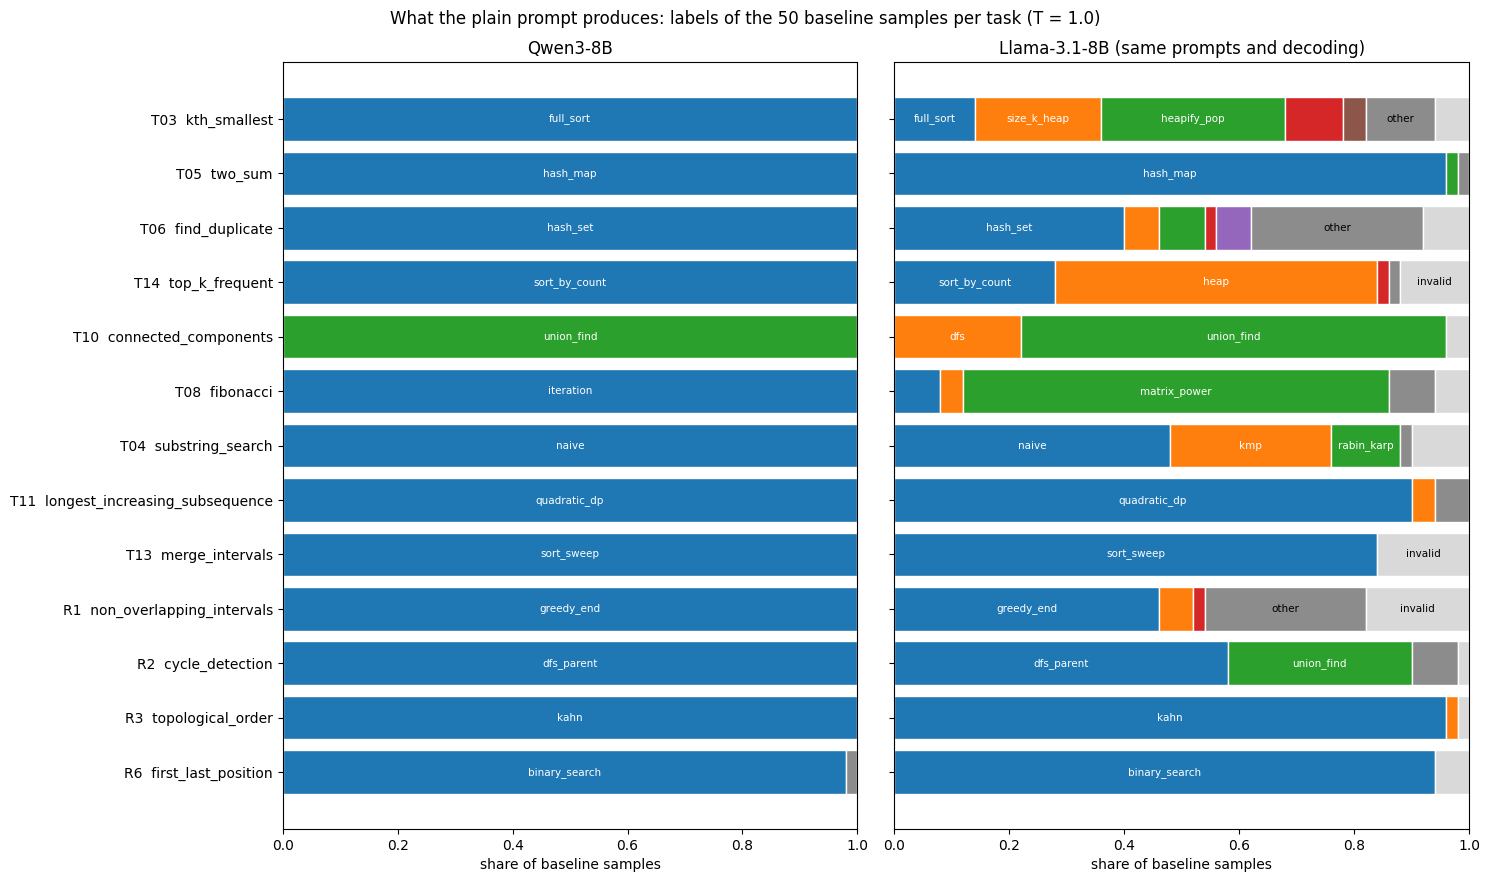

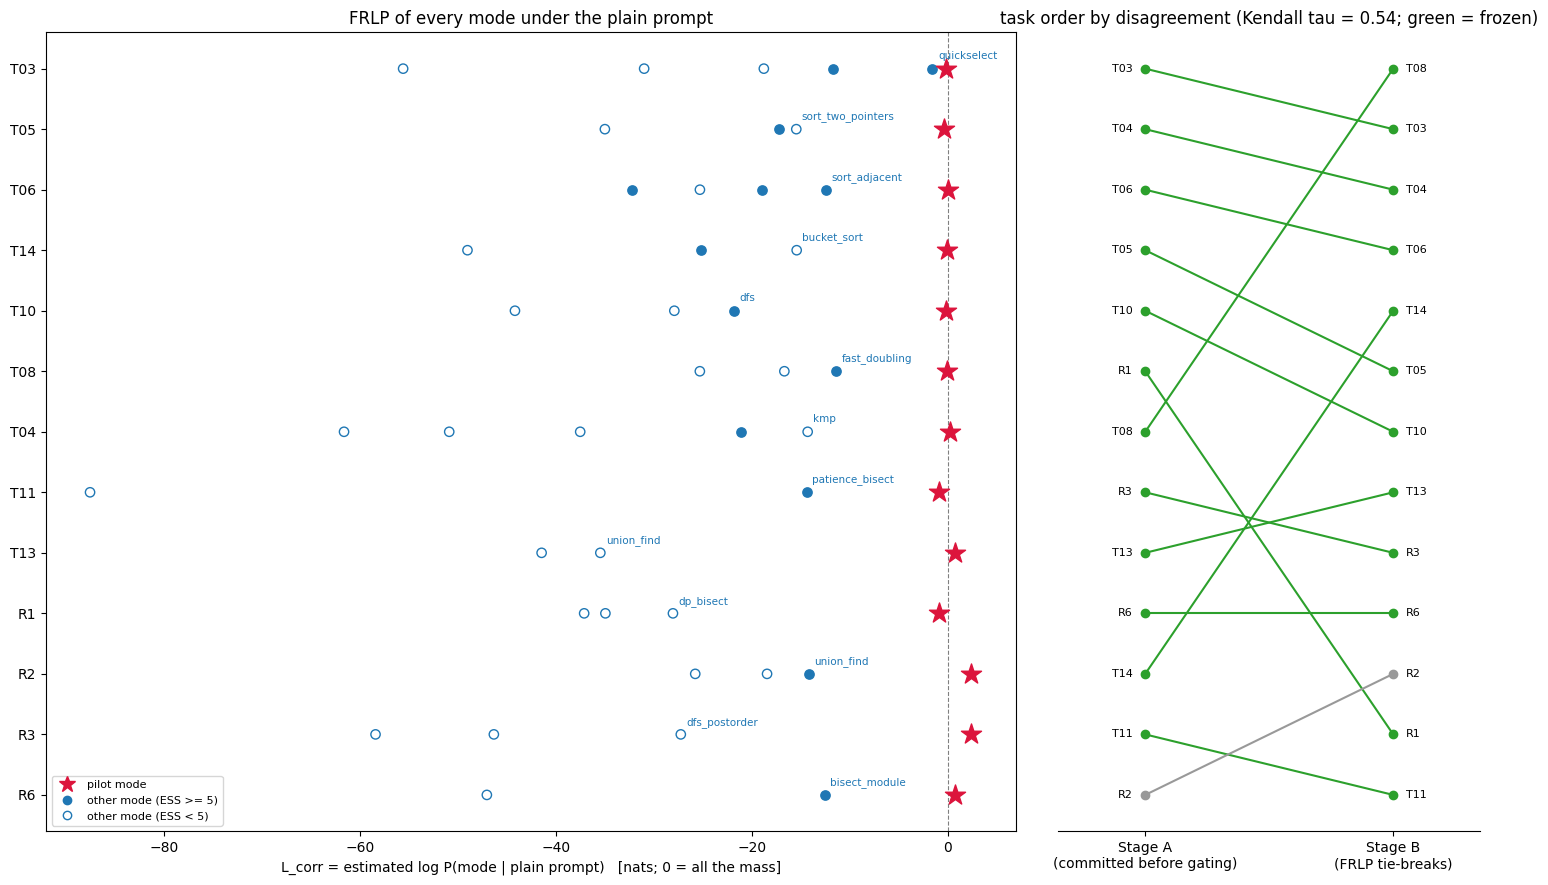

In [23]:
palette = plt.get_cmap("tab10").colors
height = 0.55 * len(TASK_ORDER) + 1.8


def _shares(rows: list[dict], t: str) -> dict:
    labs = [r["label"] for r in rows if r["task"] == t]
    return {k: v / max(len(labs), 1) for k, v in Counter(labs).items()}


# ---- Figure 1: label shares of the baseline samples, Qwen3-8B vs Llama-3.1-8B ----
fig, axes = plt.subplots(1, 2, figsize=(15, height), sharey=True)
for ax, (name, rows_) in zip(axes, [("Qwen3-8B", pilot_rows), ("Llama-3.1-8B (same prompts and decoding)", llama_rows)]):
    for i, t in enumerate(TASK_ORDER):
        modes = list(TASKS[t]["modes"])
        sh, left = _shares(rows_, t), 0.0
        for k in modes + ["other", "invalid"]:
            v = sh.get(k, 0.0)
            if v <= 0:
                continue
            col = palette[modes.index(k) % 10] if k in modes else ("0.55" if k == "other" else "0.85")
            ax.barh(i, v, left=left, color=col, edgecolor="white", height=0.8)
            if v >= 0.12:
                ax.text(left + v / 2, i, k[:16], ha="center", va="center", fontsize=7.5,
                        color="white" if k in modes else "black")
            left += v
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of baseline samples")
    ax.set_title(name)
axes[0].set_yticks(range(len(TASK_ORDER)))
axes[0].set_yticklabels([f"{t}  {TASKS[t]['task_id'].split('_', 1)[1]}" for t in TASK_ORDER])
axes[0].invert_yaxis()
fig.suptitle(f"What the plain prompt produces: labels of the {N_PILOT} baseline samples per task (T = 1.0)")
plt.tight_layout()
plt.show()

# ---- Figure 2: FRLP latent mass per mode, and the Stage-A -> Stage-B task order ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, height), gridspec_kw={"width_ratios": [2.3, 1]})
for i, t in enumerate(TASK_ORDER):
    modal = stats[t]["modal_label"]
    alts = {}
    for j in TASKS[t]["modes"]:
        c = main_cells[(t, j)]
        if c["L_corr"] is None:
            continue
        if j == modal:
            ax1.scatter(c["L_corr"], i, marker="*", s=230, color="crimson", zorder=3)
        else:
            alts[j] = c["L_corr"]
            low_ess = c["ess"] is not None and c["ess"] < 5
            ax1.scatter(c["L_corr"], i, s=45, facecolors="none" if low_ess else "tab:blue", edgecolors="tab:blue", zorder=2)
    if alts:
        b = max(alts, key=alts.get)
        ax1.annotate(b, (alts[b], i), xytext=(4, 7), textcoords="offset points", fontsize=7.5, color="tab:blue")
ax1.axvline(0, color="0.5", lw=0.8, ls="--")
ax1.set_yticks(range(len(TASK_ORDER)))
ax1.set_yticklabels(TASK_ORDER)
ax1.invert_yaxis()
ax1.set_xlabel("L_corr = estimated log P(mode | plain prompt)   [nats; 0 = all the mass]")
ax1.set_title("FRLP of every mode under the plain prompt")
ax1.legend(handles=[plt.Line2D([], [], marker="*", color="crimson", ls="", ms=12, label="pilot mode"),
                    plt.Line2D([], [], marker="o", color="tab:blue", ls="", label="other mode (ESS >= 5)"),
                    plt.Line2D([], [], marker="o", mfc="none", mec="tab:blue", ls="", label="other mode (ESS < 5)")],
           loc="lower left", fontsize=8)

posA = {t: k for k, t in enumerate(stageA["order"])}
posB = {t: k for k, t in enumerate(stageB["order"])}
for t in TASK_ORDER:
    ax2.plot([0, 1], [posA[t], posB[t]], marker="o", color="tab:green" if t in frozen else "0.6")
    ax2.text(-0.05, posA[t], t, ha="right", va="center", fontsize=8)
    ax2.text(1.05, posB[t], t, ha="left", va="center", fontsize=8)
ax2.set_xlim(-0.35, 1.35)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(["Stage A\n(committed before gating)", "Stage B\n(FRLP tie-breaks)"])
ax2.set_yticks([])
ax2.invert_yaxis()
for s in ("top", "right", "left"):
    ax2.spines[s].set_visible(False)
ax2.set_title(f"task order by disagreement (Kendall tau = {tau_AB:.2f}; green = frozen)")
plt.tight_layout()
plt.show()

## Takeaways

These are the recorded findings, which the cells above re-derive from the stored samples and scores:

- **The baseline is collapsed, and the collapse is model-specific.** At T = 1.0, Qwen3-8B writes one algorithm per task, 50/50 (R6: 49/50), with Wilson CI [0.929, 1.0]. Llama-3.1-8B gets the same prompts and decoding and spreads over several modes; on T03 its modal share is 0.34. The default comes from the model, not from the task.
- **Latent mass is not zero.** FRLP puts most of the plain prompt's probability on the pilot mode: argmax π equals the pilot mode on 13/13 tasks. Some never-sampled modes still keep non-trivial mass, such as T03 quickselect at L_corr ≈ −1.5, about 0.2. Most alternatives sit 10-35 nats below the default, and some sit much lower (T11 fenwick ≈ −88).
- **The predictors of the substitute disagree.** Free-form association is near-deterministic, for example "alternative to a full sort" → quickselect 20/20. Proximity nominates a different mode on most modal events, and FRLP tie-breaks reorder the tasks (Kendall τ ≈ 0.54). This is why the bench freezes its order and nominations before any ban experiment.
- **Caveats** recorded by the artifact:
  - 34/54 FRLP cells have Kish ESS < 5;
  - batch-dependent vLLM scoring differences reach 0.62 nat;
  - some exotic modes are hard to force (R3 layering adherence 0.04, R3 source removal 0.10), so their cells are `insufficient`.

**Configuration and scale.** The configuration cell already uses the original values: 13 tasks, 50 pilot samples, 20 association answers, M_j = 30, proximity cap 30, 1000 / 300 / 200 / 1000 resamples. With these values the whole notebook runs in well under a minute on a CPU and matches the recorded run exactly. Lower values give a quicker, rougher pass.

Re-generating the samples or likelihood scores needs the artifact repository, vLLM 0.11 and a CUDA GPU with ≥ 16 GB:

```
method.py gen --job A
method.py label
method.py score
...
```

The artifact's `reproducibility.md` lists the exact sequence with seeds and runtimes.